# MedSAM: Segment Anything in Medical Images (full demo)

**Team Sneaky Hacksaw** (Abeer, Mind, Enzo, Eloise) - BE5370 IMgVultr Capital investor demo

Paper: Ma J, He Y, Li F, Han L, You C, Wang B. *Segment anything in medical images.* **Nature Communications 15, 654 (2024)**.
https://doi.org/10.1038/s41467-024-44824-z

Code: https://github.com/bowang-lab/MedSAM

### What is MedSAM?
- Meta's Segment Anything Model (SAM) works great on normal photos but it was never trained on medical images, and it
  struggles with weak edges and low contrast
- MedSAM is SAM fine-tuned on **1,570,263 medical image-mask pairs** from **10 imaging modalities** and **30+ cancer types**
- You draw a **box** around what you want and MedSAM outlines it. One model for CT, MRI, ultrasound, X-ray, endoscopy,
  dermoscopy, fundus, pathology, OCT and mammography

### Plan
I go through the paper figure by figure and try to redo the examples myself on public data.

| Section | What | Paper |
|---|---|---|
| 1 | Load MedSAM and SAM | Methods |
| 2 | How MedSAM works, step by step, on the authors' own example | Fig. 2b |
| 3 | Pre-processing (CT windows, percentile clipping) | Methods |
| 4 | EDA: one image from each of the 10 modalities | Fig. 1, 2a |
| 5 | MedSAM vs SAM on all 10 modalities | Fig. 1 |
| 6 | Liver cancer CT, brain cancer MRI, breast cancer US, polyp endoscopy | Fig. 3 |
| 7 | Fetal head US + more modalities | Fig. 4 |
| 8 | How exact does the box need to be? | Methods |
| 9 | Box vs point prompt | Suppl. Fig. 1 |
| 10 | 3D tumor + the faster annotation pipeline | Fig. 5b |
| 11 | Limitation: vessels | Discussion |
| 12 | What I learned | |

Scores like in the paper: **DSC** (Dice) and **NSD** (normalized surface distance, tolerance 2), and the **Wilcoxon
signed-rank test** to compare the two models. I can't retrain the U-Net / DeepLabV3+ specialist models from the paper,
so I compare MedSAM against SAM only.

## 0. Imports

In [1]:
import os
import io
import time
import glob
import zipfile
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn.functional as F
import nibabel as nib
import pyarrow.parquet as pq
from PIL import Image
from scipy import ndimage as ndi
from scipy.stats import wilcoxon
from skimage import transform
from skimage import measure
from transformers import SamModel, SamProcessor

In [2]:
np.random.seed(42)
torch.manual_seed(42)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(device)

cuda


This is a demo, so only a few images per dataset. Make these bigger if you want more reliable numbers.

In [3]:
N_IMAGES = 5      # images per dataset in sections 6 and 7
N_SMALL = 3       # images per dataset in sections 8 and 9 (these run every box many times)

### Get the data
All public. The datasets are Hugging Face copies of the original challenge data. The 10-modality demo set is in the
authors' Google Drive folder (same folder as the model checkpoint):
`gdown --folder https://drive.google.com/drive/folders/1ETWmi4AiniJeWOt6HAsYgTjYv_fkgzoN`

| Data | Modality | Used in |
|---|---|---|
| `img_demo.png` (MedSAM GitHub) | CT | section 2 |
| `test_demo/` (MedSAM Google Drive) | all 10 | sections 4-5 |
| MSD Liver, case 39 | CT | sections 3, 6, 10 |
| TCGA-LGG | MRI FLAIR | section 6 |
| BUSI | ultrasound | section 6 |
| Kvasir-SEG | endoscopy | section 6 |
| HC18 | ultrasound | section 7 |
| Montgomery County | chest X-ray | section 7 |
| ISIC 2018 | dermoscopy | section 7 |
| MoNuSeg | pathology | section 7 |
| DRIVE | fundus | section 11 |

In [4]:
DATA = '../data/paper_examples'
DEMO = '../third_party/MedSAM/work_dir/MedSAM/test_demo'
HF = 'https://huggingface.co/datasets'

files_to_get = {
    'ct_abdomen/img_demo.png': 'https://raw.githubusercontent.com/bowang-lab/MedSAM/main/assets/img_demo.png',
    'msd_liver/imagesTr/liver_39.nii.gz': HF + '/MedOtter/msd-liver/resolve/main/imagesTr/liver_39.nii.gz',
    'msd_liver/labelsTr/liver_39.nii.gz': HF + '/MedOtter/msd-liver/resolve/main/labelsTr/liver_39.nii.gz',
    'lgg_flair/train.parquet': HF + '/MedOtter/TCGA-LGG-Mask/resolve/main/data/train-00000-of-00001.parquet',
    'busi/train.parquet': HF + '/MedOtter/BUSI/resolve/main/data/train-00000-of-00001.parquet',
    'kvasir/validation.parquet': HF + '/kowndinya23/Kvasir-SEG/resolve/main/data/validation-00000-of-00001-4d65c2d2950bdc96.parquet',
    'hc18/train.parquet': HF + '/MedOtter/HC18/resolve/main/data/train-00000-of-00001.parquet',
    'isic/test_0003.parquet': HF + '/MedOtter/ISIC2018/resolve/main/data/test/test_0003.parquet',
    'monuseg/test.parquet': HF + '/MedOtter/MoNuSeg/resolve/main/data/test-00000-of-00001.parquet',
    'cxr/MontgomerySet.zip': HF + '/Famatsu123/montgomery-shenzhen-tuberculosis-cxr/resolve/main/MontgomerySet.zip',
    'drive/21.tif': HF + '/Zomba/DRIVE-digital-retinal-images-for-vessel-extraction/resolve/main/train/input/21.tif',
    'drive/21_vessels.png': HF + '/Zomba/DRIVE-digital-retinal-images-for-vessel-extraction/resolve/main/train/label/21.png',
}

for path, url in files_to_get.items():
    full_path = os.path.join(DATA, path)
    if not os.path.exists(full_path):
        print('downloading', path)
        os.makedirs(os.path.dirname(full_path), exist_ok=True)
        urllib.request.urlretrieve(url, full_path)

if not os.path.exists(os.path.join(DATA, 'cxr/MontgomerySet/CXR_png')):
    zipfile.ZipFile(os.path.join(DATA, 'cxr/MontgomerySet.zip')).extractall(os.path.join(DATA, 'cxr'))

print(sorted(os.listdir(DATA)))
print('demo set there:', os.path.isdir(DEMO))

['busi', 'ct_abdomen', 'cxr', 'download.log', 'download.sh', 'drive', 'hc18', 'idrid', 'isic', 'kvasir', 'lgg_flair', 'monuseg', 'msd_liver']
demo set there: True


## 1. Load the models

- **MedSAM**: the authors released `medsam_vit_b.pth`; I use a Hugging Face conversion so it runs with `transformers`
- **SAM**: the original `facebook/sam-vit-base` (MedSAM started from this one)

Note: the popular `wanglab/medsam-vit-base` conversion has the exact same image encoder as SAM (I found that in
notebook 01b), but the paper fine-tunes the image encoder. `flaviagiammarino/medsam-vit-base` has the fine-tuned
encoder so I use that one. Checking it here again:

In [5]:
medsam = SamModel.from_pretrained('flaviagiammarino/medsam-vit-base').to(device)
sam = SamModel.from_pretrained('facebook/sam-vit-base').to(device)
wanglab = SamModel.from_pretrained('wanglab/medsam-vit-base').to(device)
samProcessor = SamProcessor.from_pretrained('facebook/sam-vit-base')

_ = medsam.eval()
_ = sam.eval()

Could not reach the Hub ([Errno 104] Connection reset by peer). Using cached commit hash for 'flaviagiammarino/medsam-vit-base'.


In [6]:
sam_weights = sam.state_dict()
check = []
for name, model in [('flaviagiammarino', medsam), ('wanglab', wanglab)]:
    weights = model.state_dict()
    for part in ['vision_encoder', 'prompt_encoder', 'mask_decoder']:
        keys = [k for k in weights if k.startswith(part)]
        n_same = 0
        for k in keys:
            if torch.equal(weights[k], sam_weights[k]):
                n_same += 1
        check.append({'checkpoint': name, 'part': part, 'tensors': len(keys), 'identical to SAM': n_same})

pd.DataFrame(check)

,checkpoint,part,tensors,identical to SAM
0,flaviagiammarino,vision_encoder,177,0
1,flaviagiammarino,prompt_encoder,17,17
2,flaviagiammarino,mask_decoder,120,6
3,wanglab,vision_encoder,177,177
4,wanglab,prompt_encoder,17,17
5,wanglab,mask_decoder,120,24


In [7]:
del wanglab
torch.cuda.empty_cache()

The paper (Methods) gives the number of trainable parameters: **89,670,912** in the image encoder and **4,058,340** in the mask decoder.

In [8]:
n_encoder = sum(p.numel() for p in medsam.vision_encoder.parameters())
n_decoder = sum(p.numel() for p in medsam.mask_decoder.parameters())
n_prompt = sum(p.numel() for p in medsam.prompt_encoder.parameters())

print(f'image encoder:  {n_encoder:,}   paper: 89,670,912')
print(f'mask decoder:   {n_decoder:,}   paper: 4,058,340')
print(f'prompt encoder: {n_prompt:,}   (frozen in the paper)')

image encoder:  89,670,912   paper: 89,670,912
mask decoder:   4,058,340   paper: 4,058,340
prompt encoder: 6,476   (frozen in the paper)


##### Both are exactly the paper's numbers (89,670,912 and 4,058,340), so this really is the MedSAM model from the paper.

## 2. How MedSAM works (Fig. 2b)

Fig. 2b: **image -> image encoder -> image embedding**, **box -> prompt encoder**, then the **mask decoder** puts both
together. Going through it step by step with the authors' own example image from their repo (`assets/img_demo.png`)
and the box from their README:

`python MedSAM_Inference.py -i assets/img_demo.png -o ./ --box "[95,255,190,350]"`

In [9]:
demo_img = np.array(Image.open(os.path.join(DATA, 'ct_abdomen/img_demo.png')))
demo_box = np.array([95, 255, 190, 350])

print(demo_img.shape, demo_img.dtype)
print(demo_img.min(), demo_img.max())

(512, 512) uint8
0 255


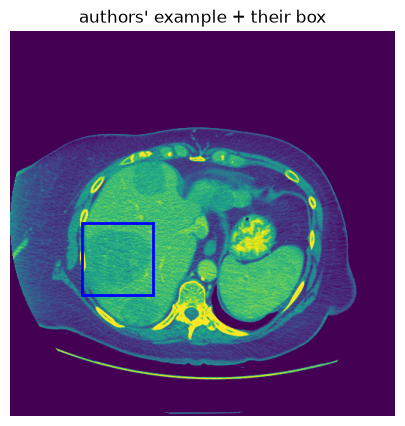

In [10]:
plt.figure(figsize=(5, 5))
plt.imshow(demo_img)
plt.gca().add_patch(plt.Rectangle((95, 255), 190 - 95, 350 - 255, fill=False, edgecolor='blue', linewidth=2))
plt.title('authors\' example + their box')
plt.axis('off')
plt.show()

##### The box is around the big dark round thing in the liver, which looks like a liver tumor.

### Step 1: pre-processing
From their `MedSAM_Inference.py`: make it 3 channels, resize to 1024 x 1024 (bicubic), scale to 0-1. No ImageNet
normalization (SAM uses that, MedSAM doesn't).

In [11]:
def to_3_channels(img):
    if img.ndim == 2:
        img = np.repeat(img[:, :, None], 3, axis=-1)
    return img[:, :, :3]

def preprocess_medsam(img_3c):
    img_1024 = transform.resize(img_3c, (1024, 1024), order=3, preserve_range=True, anti_aliasing=True)
    img_1024 = (img_1024 - img_1024.min()) / np.clip(img_1024.max() - img_1024.min(), 1e-8, None)
    return img_1024

In [12]:
demo_3c = to_3_channels(demo_img)
demo_1024 = preprocess_medsam(demo_3c)

print(demo_3c.shape)
print(demo_1024.shape, demo_1024.min(), demo_1024.max())

(512, 512, 3)
(1024, 1024, 3) 0.0 1.0


### Step 2: image encoder
The ViT splits the 1024 x 1024 image into 16 x 16 patches (64 x 64 = 4096 patches) and gives back a 256 x 64 x 64
embedding. This is the slow part and only runs once per image.

In [13]:
def medsam_embedding(img_3c):
    img_1024 = preprocess_medsam(img_3c)
    x = torch.tensor(img_1024, dtype=torch.float32).permute(2, 0, 1).unsqueeze(0).to(device)
    with torch.no_grad():
        emb = medsam.get_image_embeddings(x)
    return emb

In [14]:
demo_emb = medsam_embedding(demo_3c)    # first call is slower (GPU warm up)

t0 = time.time()
demo_emb = medsam_embedding(demo_3c)
t_encoder = time.time() - t0

print(demo_emb.shape)
print(f'encoder: {t_encoder * 1000:.0f} ms')

torch.Size([1, 256, 64, 64])
encoder: 2128 ms


### Step 3: prompt encoder
The box is just 2 corners (top left, bottom right). It gets scaled to the 1024 grid and each corner becomes a
vector of 256 numbers (positional encoding).

In [15]:
H, W = demo_img.shape[:2]
box_1024 = demo_box / np.array([W, H, W, H]) * 1024
print(demo_box, '->', box_1024)

[ 95 255 190 350] -> [190. 510. 380. 700.]


In [16]:
box_tensor = torch.tensor(box_1024, dtype=torch.float32)[None, None].to(device)   # (batch, number of boxes, 4)
with torch.no_grad():
    sparse_emb, dense_emb = medsam.prompt_encoder(input_points=None, input_labels=None,
                                                  input_boxes=box_tensor, input_masks=None)
print('box embedding:', sparse_emb.shape)     # 2 tokens (the 2 corners) x 256
print('dense embedding:', dense_emb.shape)    # no mask given, so this is a learned "no mask" embedding

box embedding: torch.Size([1, 1, 2, 256])
dense embedding: torch.Size([1, 256, 64, 64])


### Step 4: mask decoder
2 transformer layers mix the image embedding with the box tokens, then 2 transposed convolutions make a 256 x 256 mask.
Then sigmoid, resize back to the image size, threshold 0.5. Same as `medsam_inference()` in their repo.

In [17]:
t0 = time.time()
with torch.no_grad():
    out = medsam(image_embeddings=demo_emb, input_boxes=box_tensor, multimask_output=False)
t_decoder = time.time() - t0

print(out.pred_masks.shape)
print('predicted IoU:', out.iou_scores.item())
print(f'decoder: {t_decoder * 1000:.0f} ms (encoder was {t_encoder * 1000:.0f} ms)')

torch.Size([1, 1, 1, 256, 256])
predicted IoU: 0.6177145838737488
decoder: 30 ms (encoder was 2128 ms)


In [18]:
low_res = torch.sigmoid(out.pred_masks[0, 0, 0])
prob = F.interpolate(low_res[None, None], size=(H, W), mode='bilinear', align_corners=False)[0, 0]
demo_mask = prob.cpu().numpy() > 0.5

print(low_res.shape, '->', demo_mask.shape)
print('pixels in the mask:', demo_mask.sum())

torch.Size([256, 256]) -> (512, 512)
pixels in the mask: 5054


Putting steps 3 and 4 in one function (with a loop so I can give it lots of boxes at once):

In [19]:
def medsam_box(emb, boxes, H, W):
    boxes = np.array(boxes, dtype=float).reshape(-1, 4)
    masks = []
    for i in range(0, len(boxes), 50):        # 50 boxes at a time so it fits on the GPU
        b = boxes[i:i + 50] / np.array([W, H, W, H]) * 1024
        b = torch.tensor(b, dtype=torch.float32)[None].to(device)
        with torch.no_grad():
            out = medsam(image_embeddings=emb, input_boxes=b, multimask_output=False)
        low_res = torch.sigmoid(out.pred_masks[0, :, 0])
        prob = F.interpolate(low_res[:, None], size=(H, W), mode='bilinear', align_corners=False)[:, 0]
        masks.append(prob.cpu().numpy() > 0.5)
    return np.concatenate(masks)

In [20]:
def show_box(ax, box, color='blue', lw=1.5):
    x0, y0, x1, y1 = box
    ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor=color, linewidth=lw))

def show_mask(ax, mask, color=(1, 1, 0), alpha=0.5):
    rgba = np.zeros(mask.shape + (4,))
    rgba[mask] = list(color) + [alpha]
    ax.imshow(rgba)

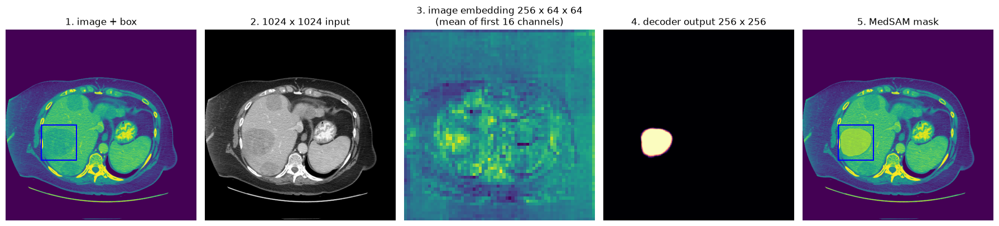

In [21]:
fig, ax = plt.subplots(1, 5, figsize=(18, 4))
ax[0].imshow(demo_img)
show_box(ax[0], demo_box)
ax[0].set_title('1. image + box')
ax[1].imshow(demo_1024)
ax[1].set_title('2. 1024 x 1024 input')
ax[2].imshow(demo_emb[0, :16].mean(dim=0).cpu().numpy(), cmap='viridis')
ax[2].set_title('3. image embedding 256 x 64 x 64\n(mean of first 16 channels)')
ax[3].imshow(low_res.cpu().numpy(), cmap='magma')
ax[3].set_title('4. decoder output 256 x 256')
ax[4].imshow(demo_img)
show_mask(ax[4], demo_mask)
show_box(ax[4], demo_box)
ax[4].set_title('5. MedSAM mask')
for a in ax:
    a.axis('off')
plt.tight_layout()
plt.show()

Fig. 2b also has several boxes on the same CT slice. I drew a few more boxes by hand (second liver tumor, spleen,
aorta). No ground truth for these, it's just to show that every extra box only needs the fast decoder.

In [22]:
more_boxes = np.array([[95, 255, 190, 350],     # their box: big liver tumor
                       [155, 178, 218, 228],    # smaller liver tumor
                       [282, 268, 388, 388],    # spleen
                       [247, 303, 277, 333]])   # aorta

t0 = time.time()
more_masks = medsam_box(demo_emb, more_boxes, H, W)
print(more_masks.shape)
print(f'{len(more_boxes)} boxes in {(time.time() - t0) * 1000:.0f} ms')

(4, 512, 512)
4 boxes in 48 ms


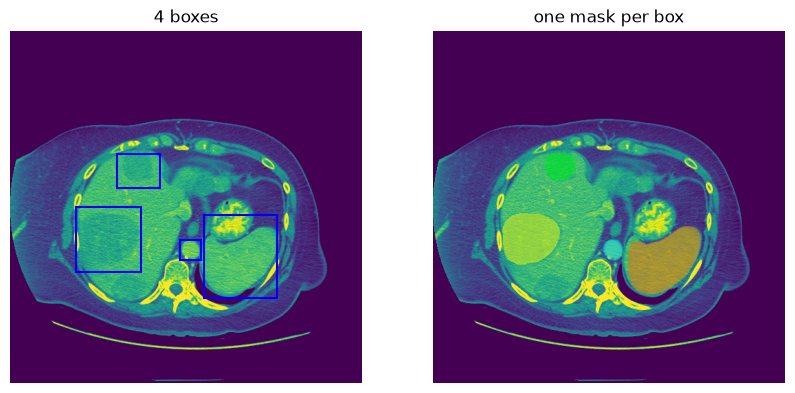

In [23]:
colors = [(1, 1, 0), (0, 1, 0), (1, 0.4, 0), (0, 0.8, 1)]

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(demo_img)
for b in more_boxes:
    show_box(ax[0], b)
ax[0].set_title('4 boxes')
ax[1].imshow(demo_img)
for m, c in zip(more_masks, colors):
    show_mask(ax[1], m, color=c)
ax[1].set_title('one mask per box')
for a in ax:
    a.axis('off')
plt.show()

## 3. Pre-processing (Methods)

From the paper:
- **CT**: window the Hounsfield units: soft tissue (W400, L40), lung (W1500, L-160), brain (W80, L40), then 0-255
- **MR, X-ray, ultrasound, mammography, OCT**: clip to the 0.5 and 99.5 percentile, then 0-255
- **RGB images** (endoscopy, dermoscopy, fundus, pathology): leave them alone

Looking at the CT windows on a real CT in Hounsfield units (MSD liver, case 39):

In [24]:
liver_img = nib.load(os.path.join(DATA, 'msd_liver/imagesTr/liver_39.nii.gz'))
liver_lab = nib.load(os.path.join(DATA, 'msd_liver/labelsTr/liver_39.nii.gz'))

liver_ct = liver_img.get_fdata().astype(np.float32)
liver_seg = np.asarray(liver_lab.dataobj).astype(int)
liver_spacing = liver_img.header.get_zooms()

print(liver_ct.shape)
print('voxel size (mm):', liver_spacing)
print('HU range:', liver_ct.min(), liver_ct.max())

(512, 512, 260)
voxel size (mm): (np.float32(1.0), np.float32(1.0), np.float32(1.0))
HU range: -1024.0 1023.0


In [25]:
np.unique(liver_seg)      # 0 background, 1 liver, 2 tumor

array([0, 1, 2])

In [26]:
def window_ct(hu, level, width):
    lo = level - width / 2
    hi = level + width / 2
    img = np.clip(hu, lo, hi)
    return ((img - lo) / (hi - lo) * 255).astype(np.uint8)

def clip_percentile(img):
    values = img[img > 0]
    lo, hi = np.percentile(values, [0.5, 99.5])
    img = np.clip(img.astype(np.float32), lo, hi)
    return ((img - lo) / (hi - lo) * 255).astype(np.uint8)

def axial(vol, z):
    return np.rot90(vol[:, :, z])      # rotate so the front of the patient is up

slice with the most tumor: 50


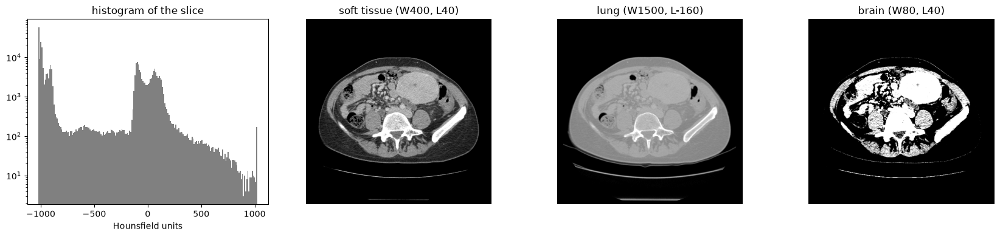

In [27]:
tumor_area_per_slice = (liver_seg == 2).sum(axis=(0, 1))
z_tumor = np.argmax(tumor_area_per_slice)
hu_slice = axial(liver_ct, z_tumor)
print('slice with the most tumor:', z_tumor)

fig, ax = plt.subplots(1, 4, figsize=(17, 4))
ax[0].hist(hu_slice.ravel(), bins=200, color='gray')
ax[0].set_yscale('log')
ax[0].set_xlabel('Hounsfield units')
ax[0].set_title('histogram of the slice')
ax[1].imshow(window_ct(hu_slice, 40, 400), cmap='gray')
ax[1].set_title('soft tissue (W400, L40)')
ax[2].imshow(window_ct(hu_slice, -160, 1500), cmap='gray')
ax[2].set_title('lung (W1500, L-160)')
ax[3].imshow(window_ct(hu_slice, 40, 80), cmap='gray')
ax[3].set_title('brain (W80, L40)')
for a in ax[1:]:
    a.axis('off')
plt.tight_layout()
plt.show()

##### The soft tissue window is the one for liver tumors (tumor = the darker area inside the liver). With the brain window the whole abdomen is white, with the lung window the liver is flat grey.

## 4. EDA: one image per modality (Fig. 1)

The authors put one example of each modality in `test_demo/` (image, expert mask and the box prompts). Before I run any
model I want to see what these look like. CT and MR are 3D, for those I take the slice where the target is biggest.

In [28]:
demo_files = sorted(glob.glob(os.path.join(DEMO, 'imgs', '*.npz')))
for f in demo_files:
    print(os.path.basename(f))

2DBox_CXR_demo.npz
2DBox_Dermoscopy_demo.npz
2DBox_Endoscopy_demo.npz
2DBox_Fundus_demo.npz
2DBox_Mammography_demo.npz
2DBox_Microscope_demo.npz
2DBox_OCT_demo.npz
2DBox_US_demo.npz
3DBox_CT_demo.npz
3DBox_MR_demo.npz


In [29]:
demo_set = {}
for f in demo_files:
    name = os.path.basename(f).replace('_demo.npz', '').replace('2DBox_', '').replace('3DBox_', '')
    img_file = np.load(f)
    gt_file = np.load(f.replace('/imgs/', '/gts/'))
    demo_set[name] = {'imgs': img_file['imgs'], 'boxes': img_file['boxes'], 'gts': gt_file['gts']}
    print(f"{name:12s} imgs {str(img_file['imgs'].shape):18s} boxes {str(img_file['boxes'].shape):8s} labels {np.unique(gt_file['gts']).tolist()}")

CXR          imgs (256, 256, 3)      boxes (1, 4)   labels [0, 1]
Dermoscopy   imgs (1024, 1024, 3)    boxes (1, 4)   labels [0, 1]
Endoscopy    imgs (1080, 1920, 3)    boxes (1, 4)   labels [0, 1]


Fundus       imgs (1934, 2576, 3)    boxes (1, 4)   labels [0, 1]
Mammography  imgs (2604, 1726, 3)    boxes (4, 4)   labels [0, 1, 2, 3, 4]
Microscope   imgs (522, 775, 3)      boxes (22, 4)  labels [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22]
OCT          imgs (512, 512, 3)      boxes (4, 4)   labels [0, 1, 2, 3, 4]
US           imgs (420, 580, 3)      boxes (1, 4)   labels [0, 1]


CT           imgs (10, 512, 512)     boxes (2, 6)   labels [0, 1, 2]
MR           imgs (74, 240, 240)     boxes (1, 6)   labels [0, 1]


##### The 3D ones (CT, MR) have boxes with 6 numbers (x0, y0, z0, x1, y1, z1), the 2D ones have 4. Microscopy has 22 cells, so 22 boxes.

For the plots and the table I need one 2D image per modality:

In [30]:
def pick_2d(d):
    if d['boxes'].shape[1] == 6:                         # 3D: slice with the most target
        z = np.argmax((d['gts'] > 0).sum(axis=(1, 2)))
        return d['imgs'][z], d['gts'][z]
    return d['imgs'], d['gts']

eda_rows = []
for name, d in demo_set.items():
    img, gt = pick_2d(d)
    is_gray = img.ndim == 2 or np.array_equal(img[:, :, 0], img[:, :, 1])
    eda_rows.append({'modality': name,
                     'height': img.shape[0],
                     'width': img.shape[1],
                     'gray or RGB': 'gray' if is_gray else 'RGB',
                     'number of targets': len(d['boxes']),
                     'target % of image': 100 * (gt > 0).mean(),
                     'mean intensity': img.mean()})
eda_df = pd.DataFrame(eda_rows)
eda_df.round(2)

,modality,height,width,gray or RGB,number of targets,target % of image,mean intensity
0,CXR,256,256,gray,1,13.93,67.54
1,Dermoscopy,1024,1024,RGB,1,25.99,141.06
2,Endoscopy,1080,1920,RGB,1,42.12,83.94
3,Fundus,1934,2576,RGB,1,4.43,31.43
4,Mammography,2604,1726,gray,4,2.13,47.50
5,Microscope,522,775,RGB,22,58.35,200.39
6,OCT,512,512,gray,4,1.86,51.30
7,US,420,580,gray,1,2.60,101.21
8,CT,512,512,gray,2,0.92,47.70
9,MR,240,240,gray,1,4.58,50.73


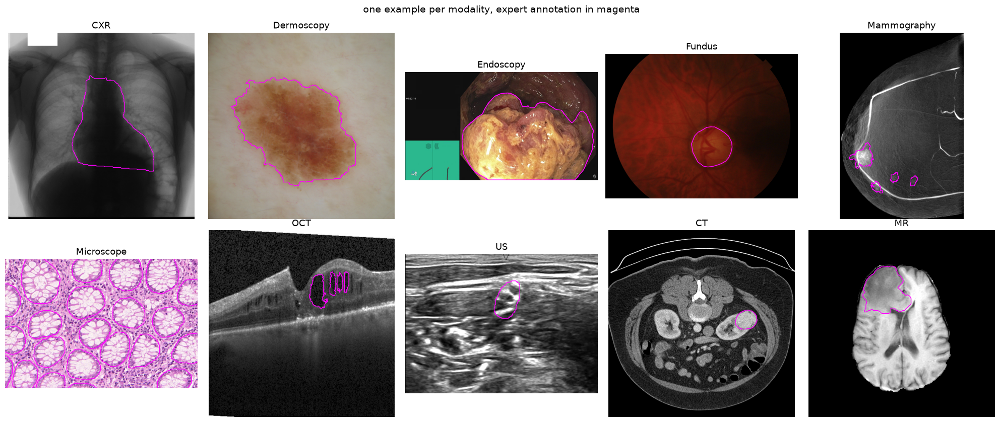

In [31]:
fig, ax = plt.subplots(2, 5, figsize=(20, 8.5))
for a, (name, d) in zip(ax.flat, demo_set.items()):
    img, gt = pick_2d(d)
    a.imshow(img, cmap='gray')
    for label in np.unique(gt)[1:]:
        a.contour(gt == label, [0.5], colors='magenta', linewidths=1)
    a.set_title(name, fontsize=13)
    a.axis('off')
plt.suptitle('one example per modality, expert annotation in magenta', fontsize=14)
plt.tight_layout()
plt.show()

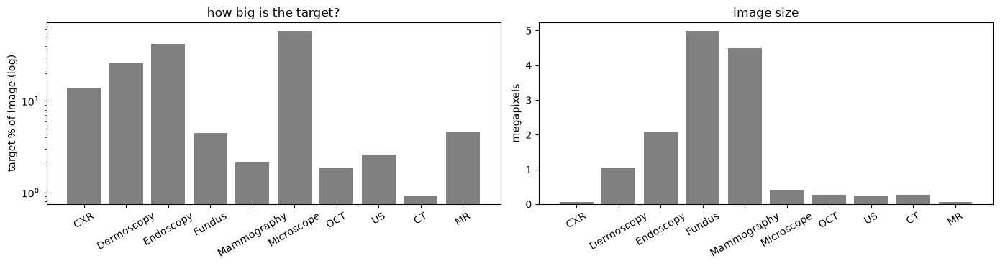

In [32]:
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
ax[0].bar(eda_df['modality'], eda_df['target % of image'], color='gray')
ax[0].set_yscale('log')
ax[0].set_ylabel('target % of image (log)')
ax[0].set_title('how big is the target?')
ax[1].bar(eda_df['modality'], eda_df['height'] * eda_df['width'] / 1e6, color='gray')
ax[1].set_ylabel('megapixels')
ax[1].set_title('image size')
for a in ax:
    a.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

##### Really different images: gray vs RGB, a 0.07 megapixel X-ray vs a 4.5 megapixel mammogram, one big polyp vs 22 small cells. One model has to deal with all of that.

The paper's Fig. 2a shows how many training images each modality had (numbers read from the figure):

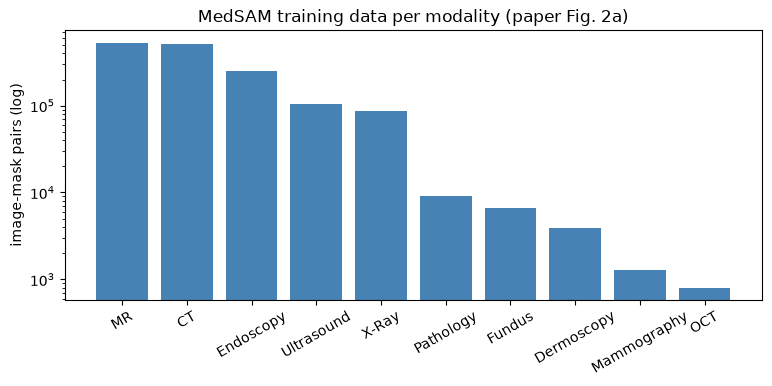

MR + CT + endoscopy = 85.7 % of the training data


In [33]:
train_counts = {'MR': 531855, 'CT': 507016, 'Endoscopy': 249690, 'Ultrasound': 105468, 'X-Ray': 87035,
                'Pathology': 9017, 'Fundus': 6710, 'Dermoscopy': 3900, 'Mammography': 1294, 'OCT': 803}

plt.figure(figsize=(9, 3.5))
plt.bar(train_counts.keys(), train_counts.values(), color='steelblue')
plt.yscale('log')
plt.ylabel('image-mask pairs (log)')
plt.title('MedSAM training data per modality (paper Fig. 2a)')
plt.xticks(rotation=30)
plt.show()

top3 = train_counts['MR'] + train_counts['CT'] + train_counts['Endoscopy']
print(f'MR + CT + endoscopy = {100 * top3 / sum(train_counts.values()):.1f} % of the training data')

##### Mammography and OCT have about 500x fewer training images than MR. The paper says in the Discussion that this could make it worse on those, so I'll check that in the next section.

## 5. MedSAM vs SAM on all 10 modalities

Same image, same boxes, two models. SAM gets its own pre-processing (`SamProcessor`: long side to 1024, padding,
ImageNet normalization). For 3D CT and MR the paper goes slice by slice with a box on each slice, so I make a box
on every slice from the expert mask.

First the SAM functions and the scores:

In [34]:
def sam_embedding(img_3c):
    inputs = samProcessor(img_3c, return_tensors='pt').to(device)
    with torch.no_grad():
        emb = sam.get_image_embeddings(inputs['pixel_values'])
    return {'emb': emb, 'original_size': inputs['original_sizes'].cpu(), 'reshaped_size': inputs['reshaped_input_sizes'].cpu()}

def sam_box(sam_emb, boxes):
    H, W = sam_emb['original_size'][0].tolist()
    scale = 1024 / max(H, W)                      # SAM resizes the long side to 1024
    boxes = np.array(boxes, dtype=float).reshape(-1, 4)
    masks = []
    for i in range(0, len(boxes), 50):
        b = torch.tensor(boxes[i:i + 50] * scale, dtype=torch.float32)[None].to(device)
        with torch.no_grad():
            out = sam(image_embeddings=sam_emb['emb'], input_boxes=b, multimask_output=False)
        m = samProcessor.image_processor.post_process_masks(out.pred_masks.cpu(), sam_emb['original_size'], sam_emb['reshaped_size'])
        masks.append(m[0][:, 0].numpy())
    return np.concatenate(masks)

def sam_point(sam_emb, points):
    H, W = sam_emb['original_size'][0].tolist()
    scale = 1024 / max(H, W)
    points = np.array(points, dtype=float).reshape(-1, 2)
    p = torch.tensor(points * scale, dtype=torch.float32)[None, :, None, :].to(device)   # (1, n, 1 point each, 2)
    labels = torch.ones((1, len(points), 1), dtype=torch.long).to(device)               # 1 = foreground click
    with torch.no_grad():
        out = sam(image_embeddings=sam_emb['emb'], input_points=p, input_labels=labels, multimask_output=False)
    m = samProcessor.image_processor.post_process_masks(out.pred_masks.cpu(), sam_emb['original_size'], sam_emb['reshaped_size'])
    return m[0][:, 0].numpy()

In [35]:
def dice(pred, gt):
    pred = pred.astype(bool)
    gt = gt.astype(bool)
    if pred.sum() + gt.sum() == 0:
        return 1.0
    return 2 * (pred & gt).sum() / (pred.sum() + gt.sum())

def nsd(pred, gt, tol=2.0, spacing=None):
    # fraction of both borders that is within tol of the other border (paper Methods, tol = 2)
    pred = pred.astype(bool)
    gt = gt.astype(bool)
    if pred.sum() == 0 or gt.sum() == 0:
        return 0.0
    if spacing is None:
        spacing = [1.0] * pred.ndim
    # only look at the area around the 2 masks (same answer, much faster on big images and 3D volumes)
    idx = np.where(pred | gt)
    margin = int(np.ceil(tol / min(spacing))) + 2
    crop = tuple(slice(max(i.min() - margin, 0), i.max() + margin + 1) for i in idx)
    pred = np.pad(pred[crop], margin)
    gt = np.pad(gt[crop], margin)
    pred_border = pred ^ ndi.binary_erosion(pred)
    gt_border = gt ^ ndi.binary_erosion(gt)
    dist_to_gt = ndi.distance_transform_edt(~gt_border, sampling=spacing)
    dist_to_pred = ndi.distance_transform_edt(~pred_border, sampling=spacing)
    good = (dist_to_gt[pred_border] <= tol).sum() + (dist_to_pred[gt_border] <= tol).sum()
    return good / (pred_border.sum() + gt_border.sum())

def box_from_mask(m, pad=5):
    rows, cols = np.where(m)
    H, W = m.shape
    x0 = max(cols.min() - pad, 0)
    y0 = max(rows.min() - pad, 0)
    x1 = min(cols.max() + pad, W - 1)
    y1 = min(rows.max() + pad, H - 1)
    return np.array([x0, y0, x1, y1], dtype=float)

Quick test on the ultrasound demo before looping over everything:

In [36]:
d = demo_set['US']
img = to_3_channels(d['imgs'])
gt = d['gts'] > 0
H, W = gt.shape

pred_medsam = medsam_box(medsam_embedding(img), d['boxes'], H, W).any(axis=0)
pred_sam = sam_box(sam_embedding(img), d['boxes']).any(axis=0)

print(img.shape, d['boxes'])
print('MedSAM DSC', round(dice(pred_medsam, gt), 3), '| SAM DSC', round(dice(pred_sam, gt), 3))

(420, 580, 3) [[265  78 347 196]]
MedSAM DSC 0.899 | SAM DSC 0.44


Works. Now the 2D demos (8 modalities):

In [37]:
modality_rows = []
modality_examples = {}

for name, d in demo_set.items():
    if d['boxes'].shape[1] == 6:       # 3D, next cell
        continue
    img = to_3_channels(d['imgs'])
    gt = d['gts'] > 0
    H, W = gt.shape
    pred_medsam = medsam_box(medsam_embedding(img), d['boxes'], H, W).any(axis=0)
    pred_sam = sam_box(sam_embedding(img), d['boxes']).any(axis=0)

    modality_rows.append({'modality': name,
                          'MedSAM DSC': dice(pred_medsam, gt), 'SAM DSC': dice(pred_sam, gt),
                          'MedSAM NSD': nsd(pred_medsam, gt), 'SAM NSD': nsd(pred_sam, gt)})
    modality_examples[name] = (d['imgs'], gt, d['boxes'], pred_medsam, pred_sam)
    print(name, 'done')

CXR done


Dermoscopy done


Endoscopy done


Fundus done


Mammography done


Microscope done


OCT done


US done


And the 2 3D ones, slice by slice, one box per target per slice. To keep the demo fast I only use the 10 slices in the middle of the target (the MR target is 74 slices long).

In [38]:
for name in ['CT', 'MR']:
    vol = demo_set[name]['imgs']
    gts = demo_set[name]['gts']
    pred_medsam = np.zeros(gts.shape, dtype=bool)
    pred_sam = np.zeros(gts.shape, dtype=bool)

    target_slices = np.where((gts > 0).any(axis=(1, 2)))[0]
    middle = len(target_slices) // 2
    use_slices = target_slices[max(middle - 5, 0):middle + 5]

    for z in use_slices:
        labels = np.unique(gts[z])[1:]
        if len(labels) == 0:
            continue
        boxes = []
        for label in labels:
            boxes.append(box_from_mask(gts[z] == label, pad=2))
        img = to_3_channels(vol[z])
        H, W = img.shape[:2]
        pred_medsam[z] = medsam_box(medsam_embedding(img), boxes, H, W).any(axis=0)
        pred_sam[z] = sam_box(sam_embedding(img), boxes).any(axis=0)

    gt = np.zeros(gts.shape, dtype=bool)
    gt[use_slices] = gts[use_slices] > 0          # only score the slices I segmented
    modality_rows.append({'modality': name,
                          'MedSAM DSC': dice(pred_medsam, gt), 'SAM DSC': dice(pred_sam, gt),
                          'MedSAM NSD': nsd(pred_medsam, gt), 'SAM NSD': nsd(pred_sam, gt)})
    z = np.argmax(gt.sum(axis=(1, 2)))
    boxes_z = [box_from_mask(gts[z] == label, pad=2) for label in np.unique(gts[z])[1:]]
    modality_examples[name] = (vol[z], gt[z], boxes_z, pred_medsam[z], pred_sam[z])
    print(name, len(use_slices), 'of', vol.shape[0], 'slices done')

CT 10 of 10 slices done


MR 10 of 74 slices done


In [39]:
modality_df = pd.DataFrame(modality_rows)
modality_df.round(3)

,modality,MedSAM DSC,SAM DSC,MedSAM NSD,SAM NSD
0,CXR,0.956,0.891,0.710,0.337
1,Dermoscopy,0.983,0.946,0.380,0.078
2,Endoscopy,0.968,0.947,0.376,0.341
3,Fundus,0.980,0.963,0.163,0.135
4,Mammography,0.805,0.343,0.206,0.069
5,Microscope,0.966,0.818,0.671,0.160
6,OCT,0.913,0.899,0.815,0.804
7,US,0.899,0.440,0.223,0.206
8,CT,0.948,0.918,0.975,0.971
9,MR,0.943,0.843,0.960,0.827


In [40]:
modality_df[['MedSAM DSC', 'SAM DSC', 'MedSAM NSD', 'SAM NSD']].mean().round(3)

MedSAM DSC    0.936
SAM DSC       0.801
MedSAM NSD    0.548
SAM NSD       0.393
dtype: float64

To show the results I copy the style of Fig. 3c / 4c in the paper: **blue** box prompt, **yellow** segmentation,
**magenta** expert annotation, DSC in the corner.

In [41]:
def paper_panel(ax, img, gt, boxes, pred, title=''):
    ax.imshow(img, cmap='gray')
    show_mask(ax, pred, color=(1, 1, 0), alpha=0.45)
    if gt.any():
        ax.contour(gt, [0.5], colors='magenta', linewidths=1)
    for b in boxes:
        show_box(ax, b, color='blue', lw=1.2)
    ax.text(0.02, 0.97, f'DSC: {dice(pred, gt):.4f}', transform=ax.transAxes, color='yellow', fontsize=10,
            va='top', bbox=dict(facecolor='black', alpha=0.5, pad=1, edgecolor='none'))
    ax.set_title(title)
    ax.axis('off')

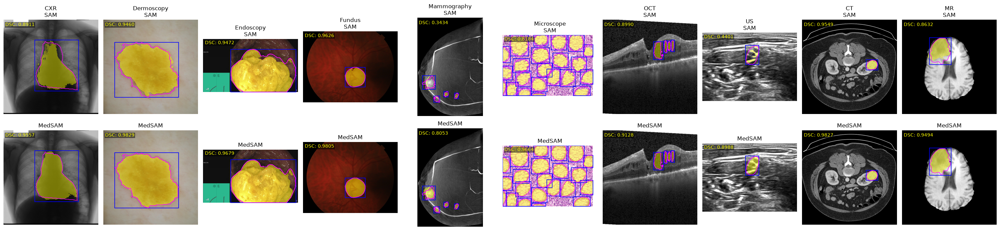

In [42]:
fig, ax = plt.subplots(2, 10, figsize=(30, 7))
for j, (name, (img, gt, boxes, pred_medsam, pred_sam)) in enumerate(modality_examples.items()):
    paper_panel(ax[0, j], img, gt, boxes, pred_sam, title=name + '\nSAM')
    paper_panel(ax[1, j], img, gt, boxes, pred_medsam, title='MedSAM')
plt.tight_layout()
plt.show()

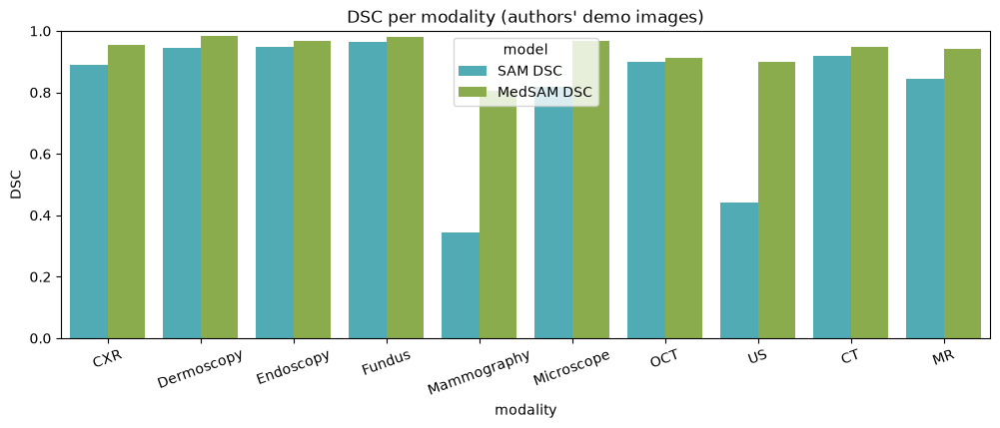

In [43]:
plot_df = modality_df.melt(id_vars='modality', value_vars=['SAM DSC', 'MedSAM DSC'], var_name='model', value_name='DSC')

plt.figure(figsize=(12, 4))
sns.barplot(data=plot_df, x='modality', y='DSC', hue='model', palette={'SAM DSC': '#3fb8c6', 'MedSAM DSC': '#8fbc3c'})
plt.ylim(0, 1)
plt.title('DSC per modality (authors\' demo images)')
plt.xticks(rotation=20)
plt.show()

##### MedSAM beats SAM on all 10 modalities: mean DSC 0.94 vs 0.80. The biggest gaps are where the paper says SAM struggles (weak edges, low contrast): ultrasound 0.90 vs 0.44 and mammography 0.81 vs 0.34 (SAM's mask leaks into the breast tissue). Mammography is also MedSAM's lowest score, which fits with it having the fewest training images (Fig. 2a).

##### NSD is much lower than DSC on the big 2D images (dermoscopy, endoscopy, fundus are 1000-2600 px wide). The tolerance is 2 pixels, which is very strict on an image that size. On CT and MR (1 mm pixels) NSD is 0.96-0.98.

## 6. Internal validation examples (Fig. 3)

Fig. 3c shows **liver cancer (CT)**, **brain cancer (MRI)**, **breast cancer (ultrasound)** and **polyp (endoscopy)**.
These kinds of datasets were in MedSAM's training data, so this is the "internal" setting. My data for each:

- liver cancer CT: MSD Liver case 39, soft tissue window, tumor slices
- brain cancer MRI: TCGA-LGG, the FLAIR channel (the brain example in Fig. 3c is FLAIR)
- breast cancer ultrasound: BUSI, malignant only
- polyp endoscopy: Kvasir-SEG

`N_IMAGES` images per dataset. One box per separate piece of the mask (5 px margin), DSC on the whole image.

Loading the images. The parquet files store each image as png bytes:

In [44]:
def decode(cell):
    return np.array(Image.open(io.BytesIO(cell['bytes'])))

N = N_IMAGES

### Liver cancer CT

In [45]:
tumor = liver_seg == 2
tumor_slices = np.where(tumor.any(axis=(0, 1)))[0]
print('tumor on', len(tumor_slices), 'slices:', tumor_slices.min(), '-', tumor_slices.max())

picked = tumor_slices[np.linspace(0, len(tumor_slices) - 1, N).astype(int)]

liver_images = []
liver_masks = []
for z in picked:
    liver_images.append(window_ct(axial(liver_ct, z), 40, 400))
    liver_masks.append(axial(tumor, z))
print(len(liver_images), liver_images[0].shape)

tumor on 76 slices: 9 - 84
5 (512, 512)


### Brain cancer MRI (FLAIR)

In [46]:
lgg = pq.read_table(os.path.join(DATA, 'lgg_flair/train.parquet')).to_pandas()
print(lgg.shape)
lgg[['patient_id', 'slice_idx', 'has_tumor']].head()

(3929, 9)


,patient_id,slice_idx,has_tumor
0,TCGA_CS_4941_19960909,1,False
1,TCGA_CS_4941_19960909,2,False
2,TCGA_CS_4941_19960909,3,False
3,TCGA_CS_4941_19960909,4,False
4,TCGA_CS_4941_19960909,5,False


In [47]:
lgg_tumor = lgg[lgg['has_tumor']].sample(N, random_state=0)

brain_images = []
brain_masks = []
for _, row in lgg_tumor.iterrows():
    img = decode(row['image'])
    brain_images.append(clip_percentile(img[:, :, 1]))       # channel 1 = FLAIR
    brain_masks.append(decode(row['mask']) > 127)
print(len(brain_images), brain_images[0].shape)

5 (256, 256)


### Breast cancer ultrasound

In [48]:
busi = pq.read_table(os.path.join(DATA, 'busi/train.parquet')).to_pandas()
print(busi.shape)
busi['class_label'].value_counts()

(780, 5)


class_label
benign       437
malignant    210
normal       133
Name: count, dtype: int64

In [49]:
busi_malignant = busi[busi['class_label'] == 'malignant'].sample(N, random_state=0)

breast_images = []
breast_masks = []
for _, row in busi_malignant.iterrows():
    img = to_3_channels(decode(row['image']))
    breast_images.append(clip_percentile(img[:, :, 0]))
    breast_masks.append(decode(row['mask']) > 127)
print(len(breast_images), breast_images[0].shape)

5 (393, 471)


### Polyp endoscopy

In [50]:
kvasir = pq.read_table(os.path.join(DATA, 'kvasir/validation.parquet')).to_pandas()
print(kvasir.shape)
kvasir_sample = kvasir.sample(N, random_state=0)

polyp_images = []
polyp_masks = []
for _, row in kvasir_sample.iterrows():
    polyp_images.append(decode(row['image']))
    polyp_masks.append(decode(row['annotation']) > 127)
print(len(polyp_images), polyp_images[0].shape)

(120, 3)
5 (546, 626, 3)


### EDA: look at a few raw images and masks first

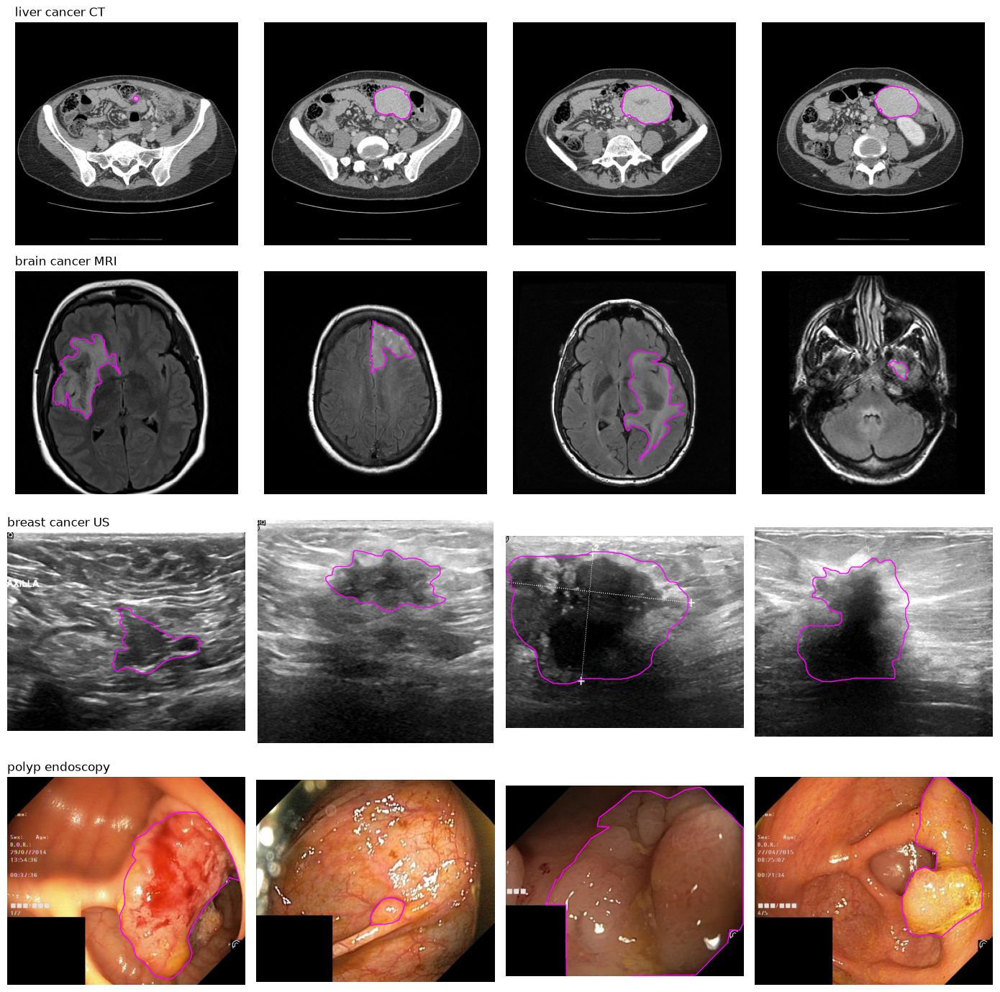

In [51]:
internal = {'liver cancer CT': (liver_images, liver_masks),
            'brain cancer MRI': (brain_images, brain_masks),
            'breast cancer US': (breast_images, breast_masks),
            'polyp endoscopy': (polyp_images, polyp_masks)}

fig, ax = plt.subplots(4, 4, figsize=(14, 14))
for r, (name, (images, masks)) in enumerate(internal.items()):
    for c in range(4):
        ax[r, c].imshow(images[c], cmap='gray')
        ax[r, c].contour(masks[c], [0.5], colors='magenta', linewidths=1)
        ax[r, c].axis('off')
    ax[r, 0].set_title(name, loc='left')
plt.tight_layout()
plt.show()

In [52]:
eda2 = []
for name, (images, masks) in internal.items():
    for img, m in zip(images, masks):
        lab, n_pieces = ndi.label(m)
        eda2.append({'dataset': name, 'height': img.shape[0], 'width': img.shape[1],
                     'target % of image': 100 * m.mean(), 'pieces': n_pieces})
eda2 = pd.DataFrame(eda2)
eda2.groupby('dataset').agg(['median', 'max']).round(1)

height       width      target % of image       pieces    
                 median  max median  max            median   max median max
dataset                                                                    
brain cancer MRI  256.0  256  256.0  256               4.8   6.3    1.0   2
breast cancer US  473.0  589  555.0  624               9.1  39.7    1.0   1
liver cancer CT   512.0  512  512.0  512               1.8   3.0    1.0   1
polyp endoscopy   530.0  546  622.0  626              17.4  63.3    1.0   2

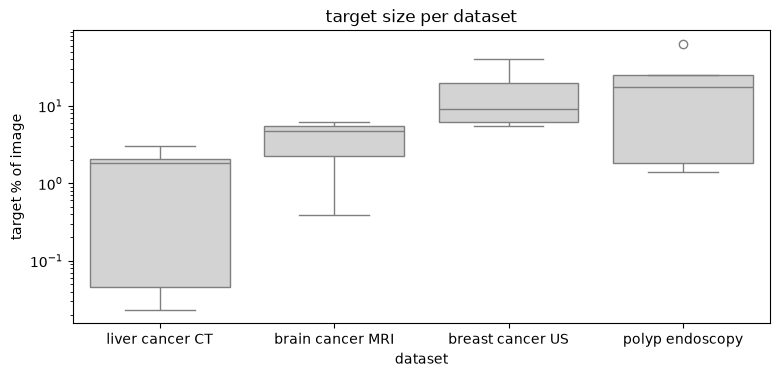

In [53]:
plt.figure(figsize=(9, 3.8))
sns.boxplot(data=eda2, x='dataset', y='target % of image', color='lightgray')
plt.yscale('log')
plt.title('target size per dataset')
plt.show()

##### Almost always 1 piece per image. The liver tumor is small on its slices (median 1.8% of the image) and polyps are big (median 17%).

### Run both models

In [54]:
def make_boxes(mask, min_pixels=50, pad=5):
    lab, n_pieces = ndi.label(mask)
    boxes = []
    for k in range(1, n_pieces + 1):
        piece = lab == k
        if piece.sum() >= min_pixels:
            boxes.append(box_from_mask(piece, pad))
    return np.array(boxes)

def run_dataset(images, masks, min_pixels=50, pad=5):
    rows = []
    preds = []
    for i in range(len(images)):
        img = to_3_channels(images[i])
        gt = masks[i]
        boxes = make_boxes(gt, min_pixels, pad)
        if len(boxes) == 0:
            continue
        H, W = gt.shape
        pred_medsam = medsam_box(medsam_embedding(img), boxes, H, W).any(axis=0)
        pred_sam = sam_box(sam_embedding(img), boxes).any(axis=0)
        rows.append({'i': i, 'MedSAM DSC': dice(pred_medsam, gt), 'SAM DSC': dice(pred_sam, gt),
                     'MedSAM NSD': nsd(pred_medsam, gt), 'SAM NSD': nsd(pred_sam, gt)})
        preds.append((img, gt, boxes, pred_medsam, pred_sam))
    return pd.DataFrame(rows), preds

In [55]:
results = {}
predictions = {}
for name, (images, masks) in internal.items():
    t0 = time.time()
    results[name], predictions[name] = run_dataset(images, masks)
    print(f'{name}: {len(results[name])} images in {time.time() - t0:.0f} s')

liver cancer CT: 5 images in 16 s


brain cancer MRI: 5 images in 15 s


breast cancer US: 5 images in 16 s


polyp endoscopy: 5 images in 16 s


In [56]:
results['polyp endoscopy'].head()

,i,MedSAM DSC,SAM DSC,MedSAM NSD,SAM NSD
0,0,0.977736,0.952337,0.540181,0.256851
1,1,0.951631,0.916201,0.687636,0.459519
2,2,0.984920,0.952329,0.650288,0.236991
3,3,0.977432,0.933862,0.648776,0.270788
4,4,0.974350,0.914395,0.876268,0.321285


The paper reports median DSC with the interquartile range, and the Wilcoxon signed-rank test (paired, same images):

In [57]:
def summary(results):
    rows = []
    for name, df in results.items():
        row = {'task': name, 'n': len(df)}
        for col in ['SAM DSC', 'MedSAM DSC', 'SAM NSD', 'MedSAM NSD']:
            med = 100 * df[col].median()
            q1 = 100 * df[col].quantile(0.25)
            q3 = 100 * df[col].quantile(0.75)
            row[col + ' %'] = f'{med:.1f} ({q1:.1f}-{q3:.1f})'
        row['Wilcoxon p'] = f"{wilcoxon(df['MedSAM DSC'], df['SAM DSC']).pvalue:.1e}"
        rows.append(row)
    return pd.DataFrame(rows).set_index('task')

summary(results)

,n,SAM DSC %,MedSAM DSC %,SAM NSD %,MedSAM NSD %,Wilcoxon p
task,,,,,,
liver cancer CT,5,96.7 (40.5-97.1),97.2 (52.0-97.5),85.9 (0.0-91.1),91.3 (6.5-93.6),1.9e-01
brain cancer MRI,5,80.0 (78.0-84.1),90.1 (88.8-90.5),53.9 (47.6-65.9),72.0 (62.9-81.8),6.2e-02
breast cancer US,5,83.4 (81.9-85.7),92.3 (90.1-94.2),16.0 (12.0-32.0),24.3 (23.5-44.0),6.2e-02
polyp endoscopy,5,93.4 (91.6-95.2),97.7 (97.4-97.8),27.1 (25.7-32.1),65.0 (64.9-68.8),6.2e-02


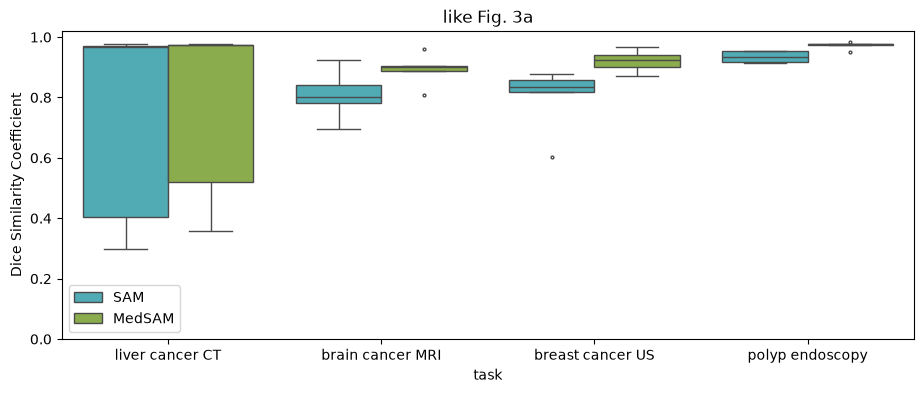

In [58]:
def paper_boxplot(results, title):
    long = []
    for name, df in results.items():
        for model in ['SAM', 'MedSAM']:
            for value in df[model + ' DSC']:
                long.append({'task': name, 'model': model, 'DSC': value})
    long = pd.DataFrame(long)

    plt.figure(figsize=(11, 4))
    sns.boxplot(data=long, x='task', y='DSC', hue='model', palette={'SAM': '#3fb8c6', 'MedSAM': '#8fbc3c'}, fliersize=2)
    plt.ylim(0, 1.02)
    plt.ylabel('Dice Similarity Coefficient')
    plt.title(title)
    plt.legend(loc='lower left')
    plt.show()

paper_boxplot(results, 'like Fig. 3a')

Like Fig. 3c: for every task the image where **MedSAM got its median DSC**, SAM on the left, MedSAM on the right.

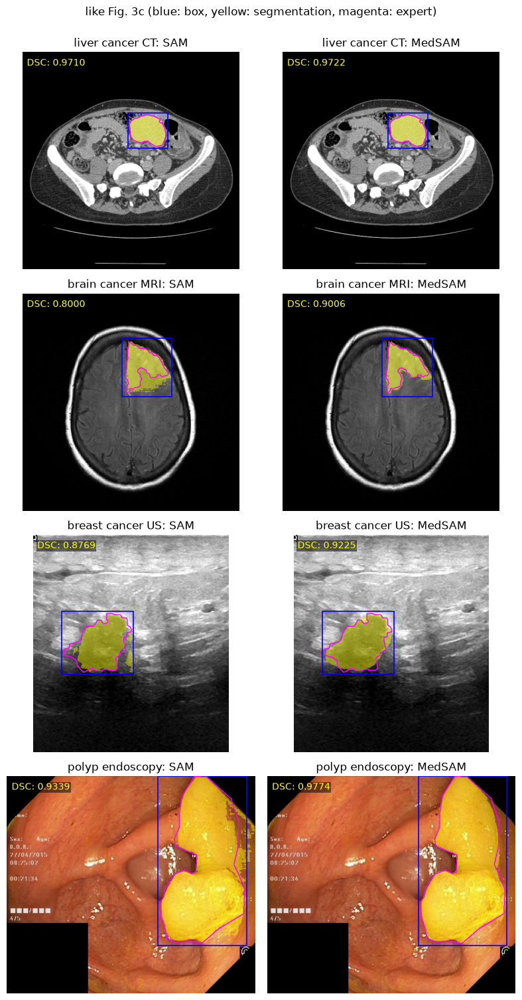

In [59]:
def median_example(df, preds):
    df = df.reset_index(drop=True)
    k = (df['MedSAM DSC'] - df['MedSAM DSC'].median()).abs().idxmin()
    return preds[k]

fig, ax = plt.subplots(4, 2, figsize=(8, 15))
for r, name in enumerate(results):
    img, gt, boxes, pred_medsam, pred_sam = median_example(results[name], predictions[name])
    paper_panel(ax[r, 0], img, gt, boxes, pred_sam, title=name + ': SAM')
    paper_panel(ax[r, 1], img, gt, boxes, pred_medsam, title=name + ': MedSAM')
plt.suptitle('like Fig. 3c (blue: box, yellow: segmentation, magenta: expert)', y=1.0)
plt.tight_layout()
plt.show()

##### MedSAM has the higher median DSC on all 4 tasks: brain cancer 90 vs 80, breast cancer 92 vs 83, polyp 98 vs 93, liver cancer 97 vs 97. The liver tumor is easy for both (clear edge in the soft tissue window), but both have a bad slice or two (lower quartile 40-52%).

##### With only 5 images the Wilcoxon test can't give p below 0.0625 (that is the smallest possible p for n = 5, when one model wins all 5), so it can't be "significant" at this demo size. Set N_IMAGES higher for a real test.

## 7. External validation examples (Fig. 4)

Fig. 4c uses datasets that were not in training: lymph node (CT), cervical cancer (MR), **fetal head (ultrasound)** and
polyp (endoscopy). I could get the **fetal head** data (HC18). I couldn't find a public download for the cervical MR
and lymph node CT, so I add other modalities from Fig. 1 instead: lungs on chest X-ray, skin lesions (dermoscopy) and
cell nuclei (pathology). I haven't checked every dataset against the training list in the paper's supplement,
so I just call them "more tasks".

### Fetal head ultrasound (HC18)

In [60]:
hc18 = pq.read_table(os.path.join(DATA, 'hc18/train.parquet')).to_pandas().sample(N, random_state=0)

head_images = []
head_masks = []
for _, row in hc18.iterrows():
    head_images.append(clip_percentile(decode(row['image'])))
    head_masks.append(decode(row['mask']) > 127)
print(len(head_images), head_images[0].shape)

5 (540, 800)


### Lungs on chest X-ray (Montgomery). Left and right lung are separate masks, so 2 boxes per image

In [61]:
cxr_files = sorted(glob.glob(os.path.join(DATA, 'cxr/MontgomerySet/CXR_png/*.png')))[:N]
print(len(cxr_files))

lung_images = []
lung_masks = []
for f in cxr_files:
    img = np.array(Image.open(f).convert('L'))
    left = np.array(Image.open(f.replace('CXR_png', 'ManualMask/leftMask'))) > 0
    right = np.array(Image.open(f.replace('CXR_png', 'ManualMask/rightMask'))) > 0
    lung_images.append(clip_percentile(img[::4, ::4]))     # images are ~4000 px, every 4th pixel is plenty
    lung_masks.append((left | right)[::4, ::4])
print(lung_images[0].shape)

5


(1005, 1223)


### Skin lesion dermoscopy (ISIC 2018)

In [62]:
isic = pq.read_table(os.path.join(DATA, 'isic/test_0003.parquet')).to_pandas().sample(N, random_state=0)

skin_images = []
skin_masks = []
for _, row in isic.iterrows():
    skin_images.append(decode(row['image']))
    skin_masks.append(decode(row['mask']) > 127)
print(len(skin_images), skin_images[0].shape)

5 (480, 640, 3)


### Nuclei in pathology (MoNuSeg). One box per nucleus, so hundreds of boxes per image

In [63]:
monuseg = pq.read_table(os.path.join(DATA, 'monuseg/test.parquet')).to_pandas().head(N)

nuclei_images = []
nuclei_masks = []
for _, row in monuseg.iterrows():
    nuclei_images.append(decode(row['image']))
    nuclei_masks.append(decode(row['mask']) > 0)
print(len(nuclei_images), nuclei_images[0].shape)
print('nuclei per image:', monuseg['num_nuclei'].tolist())

5 (1000, 1000, 3)
nuclei per image: [465, 818, 575, 475, 441]


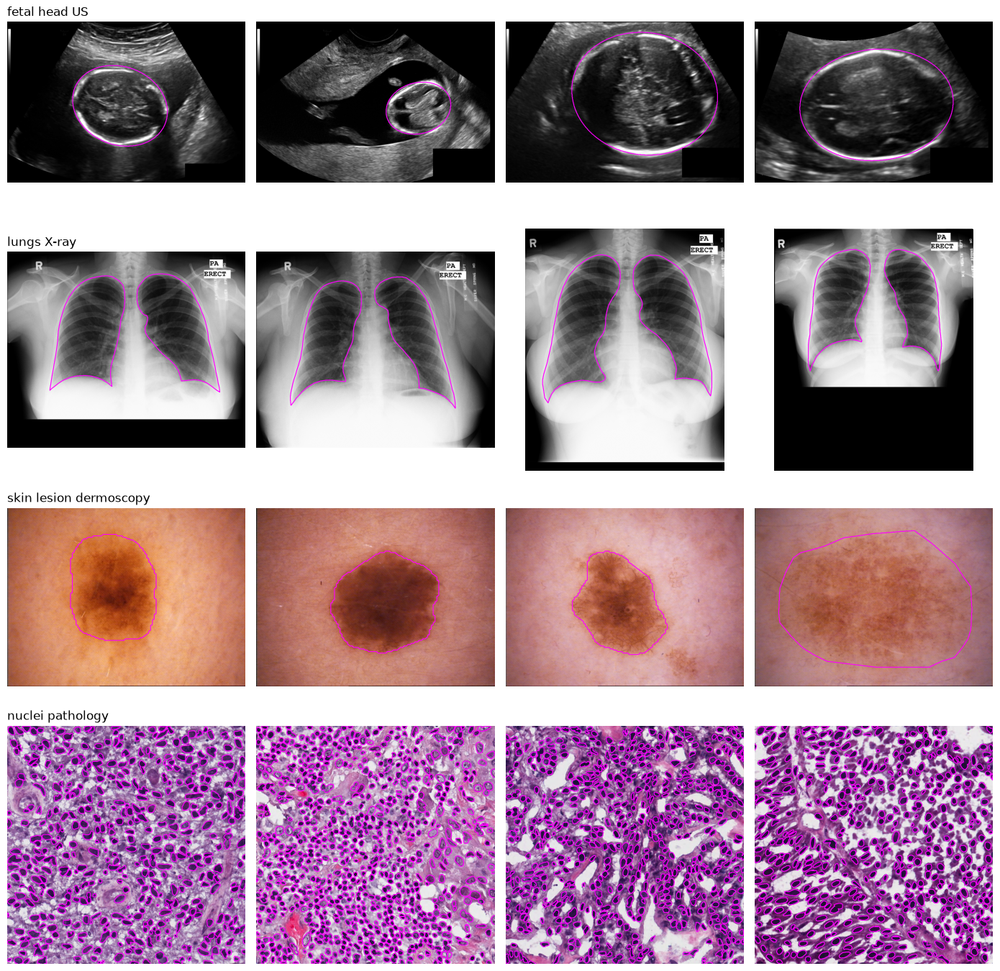

In [64]:
external = {'fetal head US': (head_images, head_masks),
            'lungs X-ray': (lung_images, lung_masks),
            'skin lesion dermoscopy': (skin_images, skin_masks),
            'nuclei pathology': (nuclei_images, nuclei_masks)}

fig, ax = plt.subplots(4, 4, figsize=(14, 14))
for r, (name, (images, masks)) in enumerate(external.items()):
    for c in range(4):
        ax[r, c].imshow(images[c], cmap='gray')
        ax[r, c].contour(masks[c], [0.5], colors='magenta', linewidths=0.8)
        ax[r, c].axis('off')
    ax[r, 0].set_title(name, loc='left')
plt.tight_layout()
plt.show()

In [65]:
results2 = {}
predictions2 = {}
for name, (images, masks) in external.items():
    t0 = time.time()
    if name == 'nuclei pathology':
        results2[name], predictions2[name] = run_dataset(images, masks, min_pixels=20, pad=2)
    else:
        results2[name], predictions2[name] = run_dataset(images, masks)
    print(f'{name}: {len(results2[name])} images in {time.time() - t0:.0f} s')

fetal head US: 5 images in 16 s


lungs X-ray: 5 images in 17 s


skin lesion dermoscopy: 5 images in 16 s


nuclei pathology: 5 images in 90 s


In [66]:
summary(results2)

,n,SAM DSC %,MedSAM DSC %,SAM NSD %,MedSAM NSD %,Wilcoxon p
task,,,,,,
fetal head US,5,78.1 (15.4-91.9),97.2 (97.1-97.4),12.3 (9.3-17.2),29.7 (25.0-35.6),6.2e-02
lungs X-ray,5,94.9 (94.1-96.0),98.4 (98.1-98.5),23.4 (22.5-24.5),56.8 (55.6-63.0),6.2e-02
skin lesion dermoscopy,5,89.1 (88.8-96.2),95.7 (94.3-97.9),10.5 (9.6-34.9),17.2 (15.9-58.7),6.2e-02
nuclei pathology,5,88.4 (86.6-88.4),67.0 (62.5-70.0),77.8 (76.7-79.7),18.5 (15.5-23.4),6.2e-02


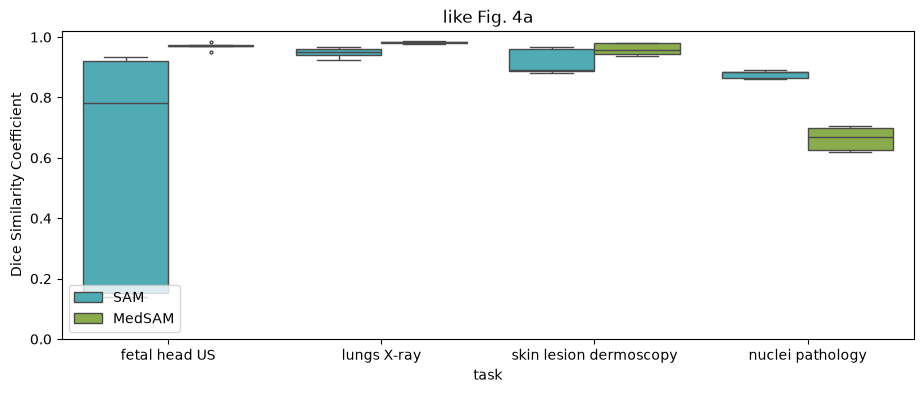

In [67]:
paper_boxplot(results2, 'like Fig. 4a')

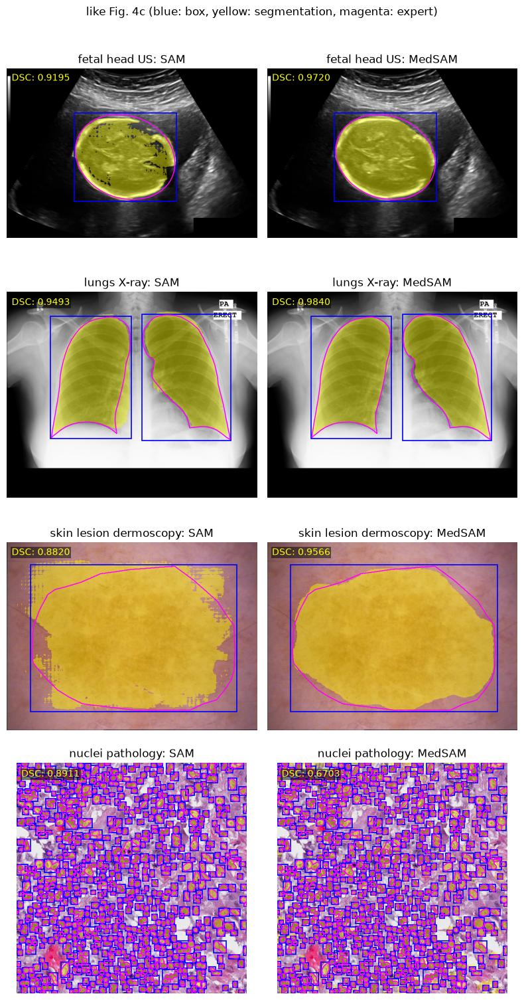

In [68]:
fig, ax = plt.subplots(4, 2, figsize=(8, 15))
for r, name in enumerate(results2):
    img, gt, boxes, pred_medsam, pred_sam = median_example(results2[name], predictions2[name])
    paper_panel(ax[r, 0], img, gt, boxes, pred_sam, title=name + ': SAM')
    paper_panel(ax[r, 1], img, gt, boxes, pred_medsam, title=name + ': MedSAM')
plt.suptitle('like Fig. 4c (blue: box, yellow: segmentation, magenta: expert)', y=1.0)
plt.tight_layout()
plt.show()

The pathology image has hundreds of boxes so you can't see anything. Zooming into one corner:

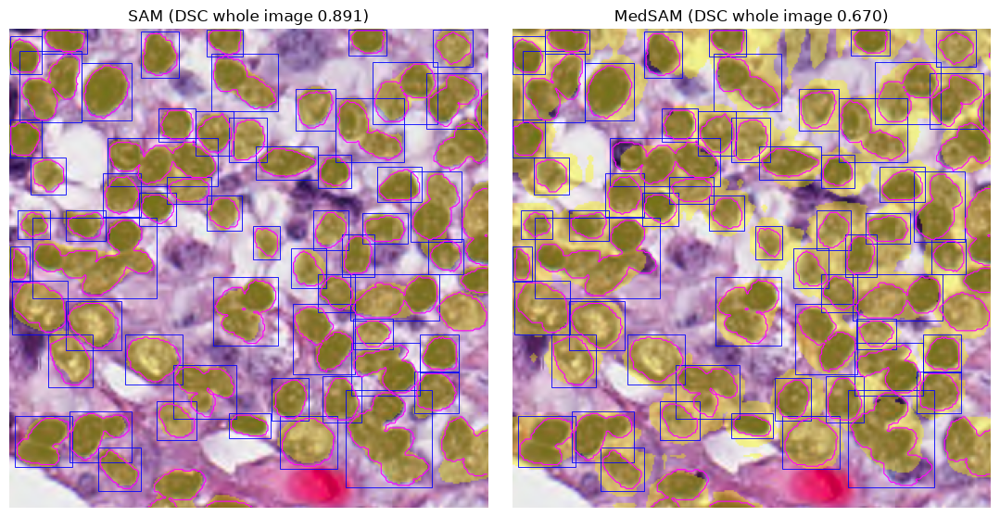

In [69]:
img, gt, boxes, pred_medsam, pred_sam = median_example(results2['nuclei pathology'], predictions2['nuclei pathology'])

fig, ax = plt.subplots(1, 2, figsize=(11, 5.5))
for a, pred, title in [(ax[0], pred_sam, 'SAM'), (ax[1], pred_medsam, 'MedSAM')]:
    a.imshow(img[:300, :300])
    show_mask(a, pred[:300, :300], alpha=0.4)
    a.contour(gt[:300, :300], [0.5], colors='magenta', linewidths=0.8)
    for b in boxes:
        if b[2] < 300 and b[3] < 300:
            show_box(a, b, lw=0.6)
    a.set_title(f'{title} (DSC whole image {dice(pred, gt):.3f})')
    a.axis('off')
plt.tight_layout()
plt.show()

##### Fetal head: MedSAM 97 vs SAM 78, and SAM is all over the place (IQR 15-92). Lungs 98 vs 95, skin lesion 96 vs 89.

##### But **nuclei in pathology go the other way: SAM 88 vs MedSAM 67**. In the zoom, MedSAM's masks spill out into the tissue between the nuclei (the yellow haze). Pathology is only 0.6% of MedSAM's training data, and these boxes are tiny (~20 px on a 1000 px image), so after resizing to 1024 a box is about one 16 x 16 patch of the image encoder.

## 8. How exact does the box need to be?

In training, the boxes came from the expert masks "with a random perturbation of 0-20 pixels" (Methods). So it should
be fine with a slightly off box. Test: move each box corner randomly by up to `shift` pixels **in the 1024 x 1024
space** (so it's the same for big and small images), 3 tries per shift, `N_SMALL` images from 4 datasets. The encoder runs
once per image and only the decoder runs again for each new box.

In [70]:
def jitter(boxes, shift, H, W, rng):
    scale = np.array([W, H, W, H]) / 1024                 # 1024 space -> image pixels
    new = boxes + rng.uniform(-shift, shift, size=boxes.shape) * scale
    new[:, [0, 2]] = np.clip(np.sort(new[:, [0, 2]], axis=1), 0, W - 1)
    new[:, [1, 3]] = np.clip(np.sort(new[:, [1, 3]], axis=1), 0, H - 1)
    return new

test = jitter(np.array([[100., 100., 200., 200.]]), 20, 512, 512, np.random.default_rng(0))
print(test)

[[102.73923375  95.39573428 190.81947048 190.33055271]]


In [71]:
rng = np.random.default_rng(0)
shifts = [0, 10, 20, 40, 80]
robust_sets = {'polyp endoscopy': internal['polyp endoscopy'], 'breast cancer US': internal['breast cancer US'],
               'brain cancer MRI': internal['brain cancer MRI'], 'fetal head US': external['fetal head US']}

robust_rows = []
for name, (images, masks) in robust_sets.items():
    for i in range(N_SMALL):
        img = to_3_channels(images[i])
        gt = masks[i]
        H, W = gt.shape
        boxes = make_boxes(gt)
        emb_medsam = medsam_embedding(img)
        emb_sam = sam_embedding(img)
        for shift in shifts:
            n_tries = 1 if shift == 0 else 3
            for t in range(n_tries):
                b = jitter(boxes, shift, H, W, rng)
                robust_rows.append({'task': name, 'shift': shift, 'model': 'MedSAM',
                                    'DSC': dice(medsam_box(emb_medsam, b, H, W).any(axis=0), gt)})
                robust_rows.append({'task': name, 'shift': shift, 'model': 'SAM',
                                    'DSC': dice(sam_box(emb_sam, b).any(axis=0), gt)})
    print(name, 'done')

robust_df = pd.DataFrame(robust_rows)
robust_df.pivot_table(index='shift', columns='model', values='DSC', aggfunc='mean').round(3)

polyp endoscopy done


breast cancer US done


brain cancer MRI done


fetal head US done


model,MedSAM,SAM
shift,,
0,0.943,0.788
10,0.939,0.784
20,0.936,0.784
40,0.904,0.800
80,0.781,0.653


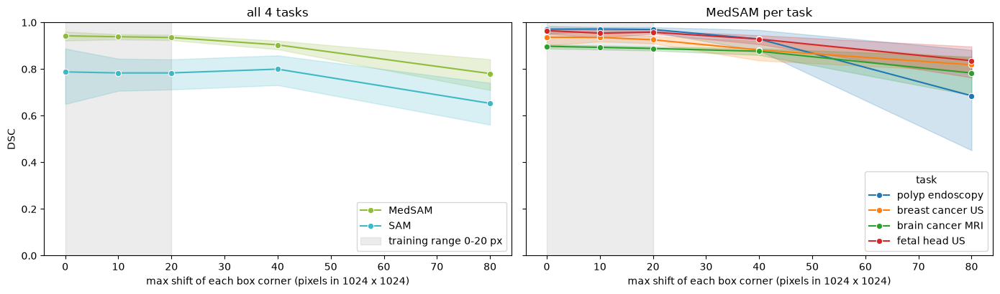

In [72]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
sns.lineplot(data=robust_df, x='shift', y='DSC', hue='model', marker='o', ax=ax[0],
             palette={'SAM': '#3fb8c6', 'MedSAM': '#8fbc3c'})
ax[0].axvspan(0, 20, color='gray', alpha=0.15, label='training range 0-20 px')
ax[0].set_title('all 4 tasks')
ax[0].legend()
sns.lineplot(data=robust_df[robust_df['model'] == 'MedSAM'], x='shift', y='DSC', hue='task', marker='o', ax=ax[1])
ax[1].axvspan(0, 20, color='gray', alpha=0.15)
ax[1].set_title('MedSAM per task')
for a in ax:
    a.set_xlabel('max shift of each box corner (pixels in 1024 x 1024)')
ax[0].set_ylim(0, 1)
plt.tight_layout()
plt.show()

##### Inside the training range (up to 20 px) MedSAM barely changes: DSC 0.943 -> 0.936. At 40 px it's 0.904, and only at 80 px it really drops (0.781). SAM is lower at every shift. So the box doesn't have to be perfect.

## 9. Box or point? (Suppl. Fig. 1)

The paper says a box is a better prompt than a point, because a point is ambiguous (did you click the lesion or the
whole organ?). SAM takes both, so I compare **SAM + 1 point** (the point inside the mask furthest from the edge),
**SAM + box** and **MedSAM + box** on the same 4 datasets. (MedSAM itself is box-only.)

In [73]:
def center_point(mask):
    dist = ndi.distance_transform_edt(mask)
    r, c = np.unravel_index(np.argmax(dist), dist.shape)
    return np.array([c, r], dtype=float)          # x, y

prompt_rows = []
prompt_examples = {}
for name, (images, masks) in robust_sets.items():
    for i in range(N_SMALL):
        img = to_3_channels(images[i])
        gt = masks[i]
        H, W = gt.shape
        boxes = make_boxes(gt)
        lab, n_pieces = ndi.label(gt)
        points = []
        for k in range(1, n_pieces + 1):
            if (lab == k).sum() >= 50:
                points.append(center_point(lab == k))
        points = np.array(points)

        emb_sam = sam_embedding(img)
        pred_point = sam_point(emb_sam, points).any(axis=0)
        pred_box = sam_box(emb_sam, boxes).any(axis=0)
        pred_medsam = medsam_box(medsam_embedding(img), boxes, H, W).any(axis=0)

        prompt_rows.append({'task': name, 'SAM + point': dice(pred_point, gt), 'SAM + box': dice(pred_box, gt),
                            'MedSAM + box': dice(pred_medsam, gt)})
        if i == 0:
            prompt_examples[name] = (img, gt, boxes, points, pred_point, pred_box, pred_medsam)

prompt_df = pd.DataFrame(prompt_rows)
prompt_df.groupby('task').mean().round(3)

,SAM + point,SAM + box,MedSAM + box
task,,,
brain cancer MRI,0.286,0.779,0.898
breast cancer US,0.619,0.764,0.937
fetal head US,0.485,0.669,0.965
polyp endoscopy,0.646,0.940,0.971


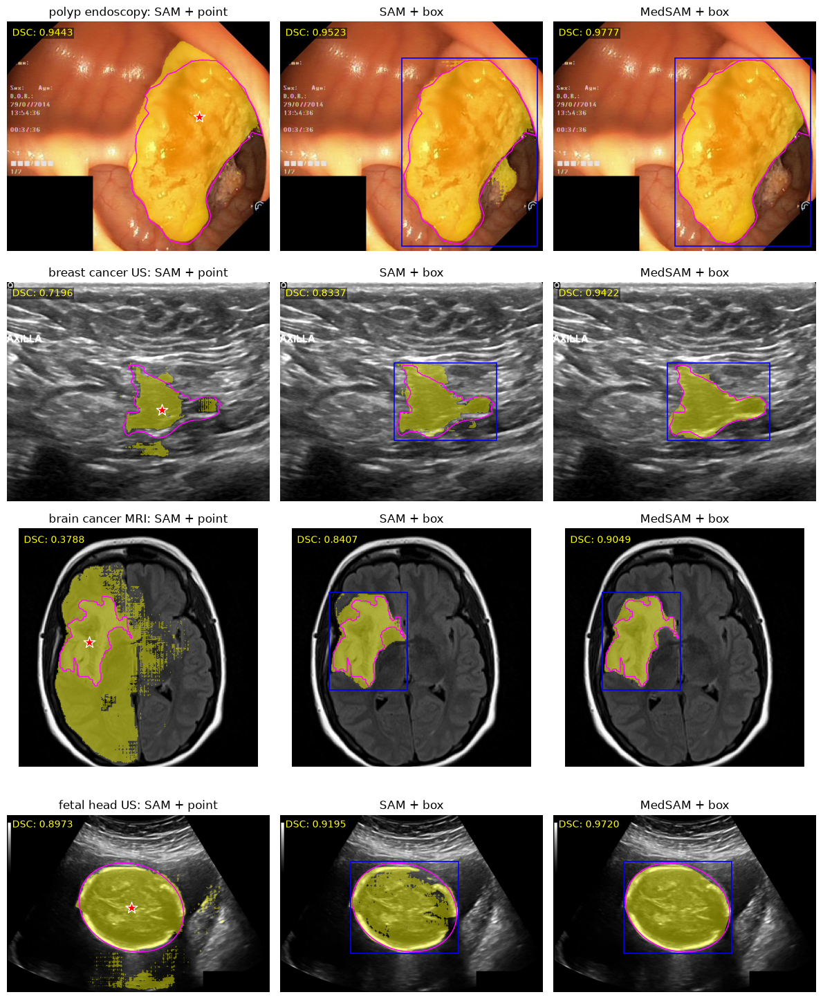

In [74]:
fig, ax = plt.subplots(4, 3, figsize=(12, 15))
for r, (name, (img, gt, boxes, points, pred_point, pred_box, pred_medsam)) in enumerate(prompt_examples.items()):
    paper_panel(ax[r, 0], img, gt, [], pred_point, title=name + ': SAM + point')
    ax[r, 0].scatter(points[:, 0], points[:, 1], c='red', marker='*', s=150, edgecolors='white')
    paper_panel(ax[r, 1], img, gt, boxes, pred_box, title='SAM + box')
    paper_panel(ax[r, 2], img, gt, boxes, pred_medsam, title='MedSAM + box')
plt.tight_layout()
plt.show()

##### For SAM, 1 point is much worse than a box on every task (brain cancer 0.29 vs 0.78, fetal head 0.49 vs 0.67). With a point SAM doesn't know how big the object is, so it picks some part of it or something around it. MedSAM + box is the best on all 4. This is the paper's argument for boxes.

## 10. 3D tumor and the faster annotation pipeline (Fig. 5b)

MedSAM is 2D so a 3D scan is done slice by slice. In the paper's annotation study (Fig. 5b), the experts didn't draw a
box on every slice. They:
1. drew the long and short axis of the tumor (the "initial marker") **every 3-10 slices**, which becomes a box
2. **interpolated** the boxes for the slices in between
3. ran MedSAM on every slice, then fixed it by hand

That cut the annotation time by **82%**. They used adrenal tumor CTs, I try the same thing on the liver tumor (MSD case 39).
My marker box = the tumor's bounding box on that slice (that is what the 2 axis lines cover).

In [75]:
lab3d, n_tumors = ndi.label(liver_seg == 2)
print('separate tumors:', n_tumors)

sizes = ndi.sum(lab3d > 0, lab3d, range(1, n_tumors + 1))
tumor3d = lab3d == (np.argmax(sizes) + 1)
tumor_zs = np.where(tumor3d.any(axis=(0, 1)))[0]
voxel_mL = np.prod(liver_spacing) / 1000

print('biggest tumor on slices', tumor_zs.min(), '-', tumor_zs.max(), f'({len(tumor_zs)} slices)')
print(f'volume: {tumor3d.sum() * voxel_mL:.1f} mL')

separate tumors: 1


biggest tumor on slices 9 - 84 (76 slices)
volume: 349.0 mL


Encode every tumor slice once and keep the embeddings:

In [76]:
t0 = time.time()
slice_emb = {}
for z in tumor_zs:
    slice_emb[z] = medsam_embedding(to_3_channels(window_ct(axial(liver_ct, z), 40, 400)))
t_enc = time.time() - t0
print(f'{len(tumor_zs)} slices in {t_enc:.1f} s ({1000 * t_enc / len(tumor_zs):.0f} ms per slice)')

76 slices in 161.5 s (2125 ms per slice)


In [77]:
def segment_volume(boxes_per_slice):
    pred = np.zeros_like(tumor3d)
    for z, box in boxes_per_slice.items():
        H, W = axial(tumor3d, z).shape
        m = medsam_box(slice_emb[z], [box], H, W)[0]
        pred[:, :, z] = np.rot90(m, k=-1)          # undo the rot90 from axial()
    return pred

def interpolated_boxes(marker_slices):
    marker_boxes = []
    for z in marker_slices:
        marker_boxes.append(box_from_mask(axial(tumor3d, z), pad=3))
    marker_boxes = np.array(marker_boxes)
    boxes = {}
    for z in tumor_zs:
        boxes[z] = np.array([np.interp(z, marker_slices, marker_boxes[:, j]) for j in range(4)])
    return boxes

Option A: a box on every slice (the most work, best case). Option B: markers every 3, 5 or 10 slices.

In [78]:
pipeline_rows = []
pipeline_preds = {}

every_slice = {}
for z in tumor_zs:
    every_slice[z] = box_from_mask(axial(tumor3d, z), pad=3)
t0 = time.time()
pipeline_preds['box on every slice'] = segment_volume(every_slice)
print(f'decoder for all {len(tumor_zs)} slices: {time.time() - t0:.2f} s')
pipeline_rows.append({'pipeline': 'box on every slice', 'boxes drawn by hand': len(tumor_zs)})

for k in [3, 5, 10]:
    markers = list(range(tumor_zs.min(), tumor_zs.max() + 1, k))
    if markers[-1] != tumor_zs.max():
        markers.append(tumor_zs.max())             # always mark the last slice too
    pipeline_preds[f'marker every {k} slices'] = segment_volume(interpolated_boxes(markers))
    pipeline_rows.append({'pipeline': f'marker every {k} slices', 'boxes drawn by hand': len(markers)})

decoder for all 76 slices: 1.16 s


In [79]:
for row in pipeline_rows:
    pred = pipeline_preds[row['pipeline']]
    row['3D DSC'] = dice(pred, tumor3d)
    row['3D NSD (2 mm)'] = nsd(pred, tumor3d, tol=2.0, spacing=liver_spacing)
    row['volume mL'] = pred.sum() * voxel_mL

pipeline_df = pd.DataFrame(pipeline_rows)
print(f'expert volume: {tumor3d.sum() * voxel_mL:.1f} mL')
pipeline_df.round(3)

expert volume: 349.0 mL


,pipeline,boxes drawn by hand,3D DSC,3D NSD (2 mm),volume mL
0,box on every slice,76,0.969,0.959,352.729
1,marker every 3 slices,26,0.969,0.957,353.371
2,marker every 5 slices,16,0.969,0.961,352.082
3,marker every 10 slices,9,0.968,0.960,349.187


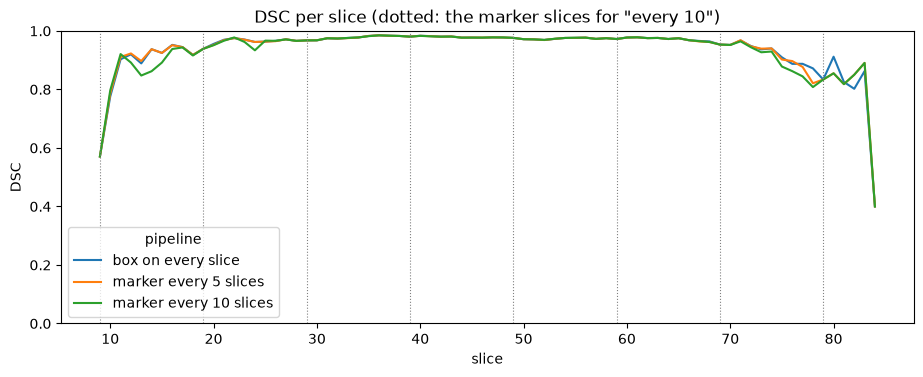

In [80]:
per_slice = []
for name in ['box on every slice', 'marker every 5 slices', 'marker every 10 slices']:
    for z in tumor_zs:
        per_slice.append({'pipeline': name, 'slice': z, 'DSC': dice(pipeline_preds[name][:, :, z], tumor3d[:, :, z])})
per_slice = pd.DataFrame(per_slice)

plt.figure(figsize=(11, 3.8))
sns.lineplot(data=per_slice, x='slice', y='DSC', hue='pipeline')
for m in range(tumor_zs.min(), tumor_zs.max() + 1, 10):
    plt.axvline(m, color='gray', linestyle=':', linewidth=0.8)
plt.ylim(0, 1)
plt.title('DSC per slice (dotted: the marker slices for "every 10")')
plt.show()

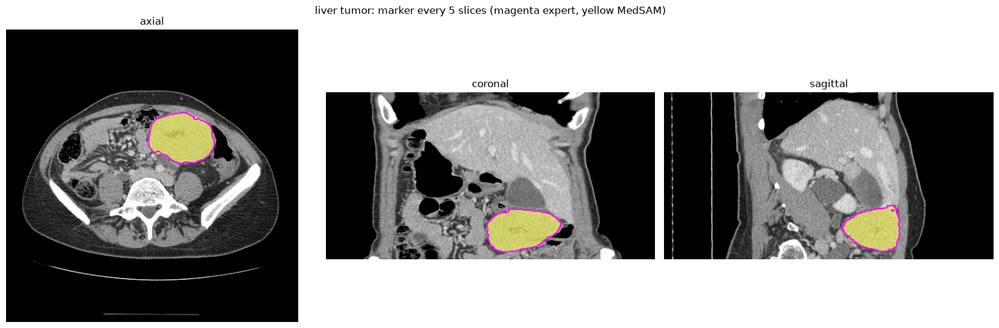

In [81]:
pred = pipeline_preds['marker every 5 slices']
cx, cy, cz = [int(c) for c in ndi.center_of_mass(tumor3d)]
z_aspect = liver_spacing[2] / liver_spacing[0]

fig, ax = plt.subplots(1, 3, figsize=(17, 5.5))
ax[0].imshow(window_ct(np.rot90(liver_ct[:, :, cz]), 40, 400), cmap='gray')
show_mask(ax[0], np.rot90(pred[:, :, cz]), alpha=0.4)
ax[0].contour(np.rot90(tumor3d[:, :, cz]), [0.5], colors='magenta')
ax[0].set_title('axial')
ax[1].imshow(window_ct(np.rot90(liver_ct[:, cy, :]), 40, 400), cmap='gray', aspect=z_aspect)
show_mask(ax[1], np.rot90(pred[:, cy, :]), alpha=0.4)
ax[1].contour(np.rot90(tumor3d[:, cy, :]), [0.5], colors='magenta')
ax[1].set_title('coronal')
ax[2].imshow(window_ct(np.rot90(liver_ct[cx, :, :]), 40, 400), cmap='gray', aspect=z_aspect)
show_mask(ax[2], np.rot90(pred[cx, :, :]), alpha=0.4)
ax[2].contour(np.rot90(tumor3d[cx, :, :]), [0.5], colors='magenta')
ax[2].set_title('sagittal')
for a in ax:
    a.axis('off')
plt.suptitle('liver tumor: marker every 5 slices (magenta expert, yellow MedSAM)')
plt.tight_layout()
plt.show()

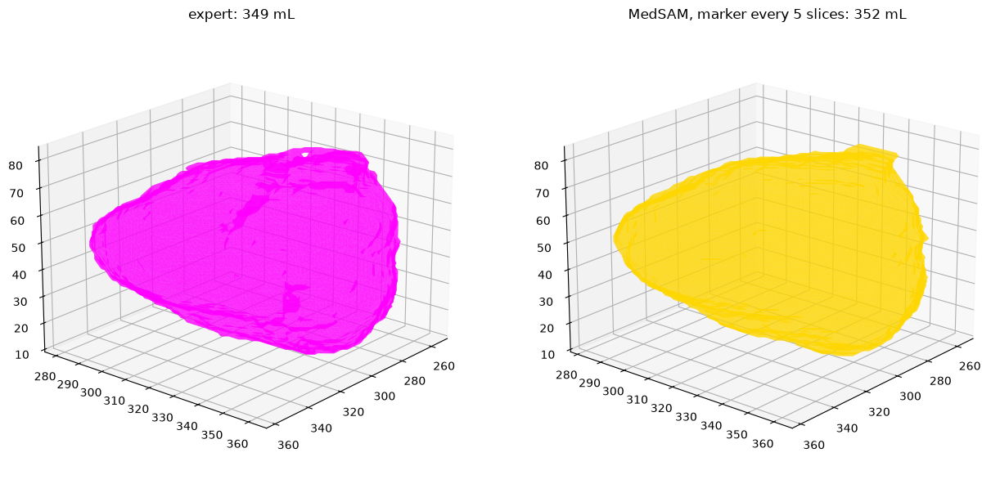

In [82]:
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

fig = plt.figure(figsize=(13, 6))
for i, (vol, title, color) in enumerate([(tumor3d, 'expert', 'magenta'), (pred, 'MedSAM, marker every 5 slices', 'gold')]):
    verts, faces, _, _ = measure.marching_cubes(vol.astype(float), 0.5, spacing=liver_spacing, step_size=2)
    a = fig.add_subplot(1, 2, i + 1, projection='3d')
    a.add_collection3d(Poly3DCollection(verts[faces], alpha=0.6, facecolor=color, edgecolor='none'))
    a.set_xlim(verts[:, 0].min(), verts[:, 0].max())
    a.set_ylim(verts[:, 1].min(), verts[:, 1].max())
    a.set_zlim(verts[:, 2].min(), verts[:, 2].max())
    a.set_title(f'{title}: {vol.sum() * voxel_mL:.0f} mL')
    a.view_init(20, 40)
plt.tight_layout()
plt.show()

The paper's own annotation-time result (Fig. 5b text: time reduced by 82.37% and 82.95% for the 2 experts):

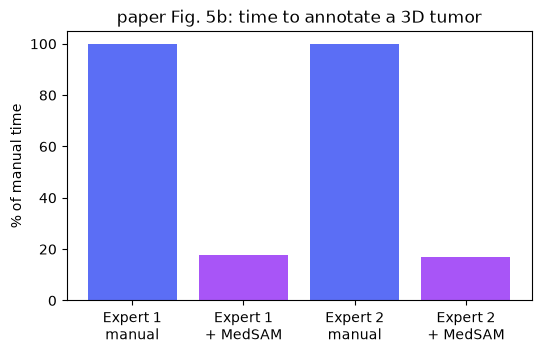

In [83]:
plt.figure(figsize=(6, 3.5))
plt.bar(['Expert 1\nmanual', 'Expert 1\n+ MedSAM', 'Expert 2\nmanual', 'Expert 2\n+ MedSAM'],
        [100, 100 - 82.37, 100, 100 - 82.95], color=['#5b6ef5', '#a855f7', '#5b6ef5', '#a855f7'])
plt.ylabel('% of manual time')
plt.title('paper Fig. 5b: time to annotate a 3D tumor')
plt.show()

##### All 4 pipelines get a 3D DSC of 0.97 and a tumor volume within 1% of the expert's 349 mL. A marker on only 9 slices (every 10) is as good as drawing 76 boxes, because the tumor changes smoothly from slice to slice so the interpolated boxes are fine. That's how most of the manual work goes away.

##### Speed: the decoder did all 76 slices in 1.2 s. The encoder took 2.1 s per slice, but I timed the bicubic resize to 1024 x 1024 on the CPU at 1.7 s, so most of that is the pre-processing, not the model.

## 11. Limitation: vessels (Discussion)

The paper says MedSAM has trouble with "vessel-like branching structures" because the box is ambiguous (arteries and
veins in a fundus image have the same box). Trying retinal vessels from DRIVE: the box around the vessel tree is
almost the whole eye.

In [84]:
eye = np.array(Image.open(os.path.join(DATA, 'drive/21.tif')).convert('RGB'))
vessels = np.array(Image.open(os.path.join(DATA, 'drive/21_vessels.png')).convert('L')) > 127
print(eye.shape, vessels.shape)

vessel_box = box_from_mask(vessels, pad=2)
box_area = (vessel_box[2] - vessel_box[0]) * (vessel_box[3] - vessel_box[1])
print(f'vessels fill {100 * vessels.sum() / box_area:.1f} % of their box')

(584, 565, 3) (584, 565)
vessels fill 8.8 % of their box


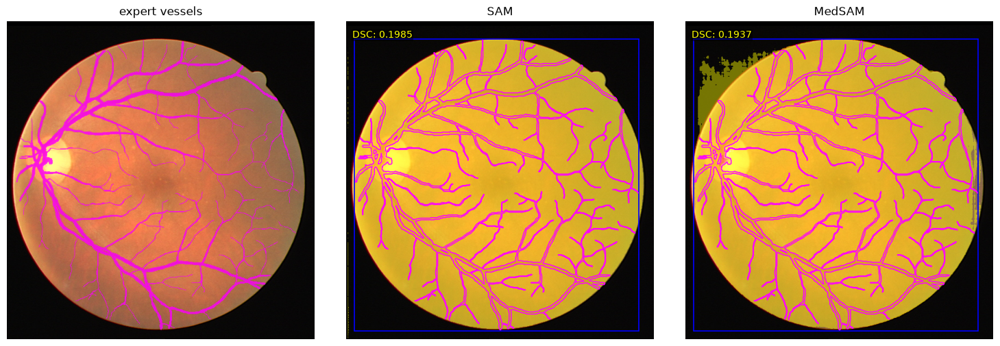

In [85]:
H, W = vessels.shape
pred_medsam = medsam_box(medsam_embedding(eye), [vessel_box], H, W)[0]
pred_sam = sam_box(sam_embedding(eye), [vessel_box])[0]

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(eye)
ax[0].imshow(np.ma.masked_equal(vessels, 0), cmap='spring', alpha=0.8)
ax[0].set_title('expert vessels')
ax[0].axis('off')
paper_panel(ax[1], eye, vessels, [vessel_box], pred_sam, title='SAM')
paper_panel(ax[2], eye, vessels, [vessel_box], pred_medsam, title='MedSAM')
plt.tight_layout()
plt.show()

##### The vessels fill only 8.8% of their box and both models just fill the whole eye (DSC 0.19). A box can't describe a thin branching tree, which is exactly the limitation the authors describe.

## 12. What I learned

| | SAM | MedSAM |
|---|---|---|
| 10 modalities (authors' demo images), mean DSC | 0.80 | **0.94** |
| brain cancer MRI, median DSC | 0.80 | **0.90** |
| breast cancer ultrasound | 0.83 | **0.92** |
| polyp endoscopy | 0.93 | **0.98** |
| liver cancer CT | 0.97 | 0.97 |
| fetal head ultrasound | 0.78 | **0.97** |
| lungs X-ray | 0.95 | **0.98** |
| skin lesion dermoscopy | 0.89 | **0.96** |
| nuclei pathology | **0.88** | 0.67 |
| retinal vessels | 0.20 | 0.19 |

1. **It's the model from the paper**: parameter counts match exactly. But check which download you use: the popular
   `wanglab` Hugging Face version has SAM's original image encoder.
2. **One model, 10 modalities**: MedSAM beat SAM on every modality in the authors' demo set, most on ultrasound and
   mammography where the edges are weak. Same picture on the Fig. 3 and Fig. 4 style tasks.
3. **Forgiving to sloppy boxes**: almost no loss up to a 20 px shift (the range used in training), and a box is a much
   better prompt than a point.
4. **3D for very little work**: 9 marker boxes instead of 76 gave the same 3D tumor (DSC 0.97, volume within 1%).
   This is the pipeline the paper used to cut annotation time by 82%.
5. **Weak spots**: tiny objects in pathology (SAM did better), thin branching structures like vessels (neither works),
   and the modalities with little training data (mammography was MedSAM's lowest score).

**For the pitch**: one promptable model replaces a separate model per modality, works on new data without retraining,
and turns hours of slice-by-slice tracing into a few boxes. The risks are the small modalities, tiny objects and
vessels, and that someone still has to draw the boxes.

**Caveats**: only 5 images per dataset here (it's a demo, `N_IMAGES` at the top), so no significance testing. No
U-Net / DeepLabV3+ comparison. Several of these public datasets were probably in MedSAM's training data. I couldn't
get the paper's cervical cancer MR and lymph node CT datasets. My GluCEST experiments are in notebooks 02 and 03.